# Qualidade dos Dados - Turnover

Notebook de teste para avaliar a qualidade dos dados do dataset de turnover (HR-Employee-Attrition).

## 1.0 - Importações

In [1]:
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

# Coluna alvo do problema de classificação.
TARGET_COLUMN = "Attrition"

# Caminho do CSV de entrada (relativo à raiz do projeto).
DATA_PATH = Path("..") / "data" / "HR-Employee-Attrition-balanced.csv"

df = pd.read_csv(DATA_PATH)
df

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,58,Yes,Travel_Rarely,601,Research & Development,7,4,Medical,1,1360,...,4,80,0,31,0,2,10,9,5,9
1,27,Yes,Travel_Frequently,1341,Human Resources,21,2,Human Resources,1,1950,...,1,80,0,0,2,3,0,0,0,0
2,50,Yes,Travel_Rarely,407,Sales,28,3,Marketing,1,2049,...,2,80,1,19,3,2,2,2,1,0
3,39,No,Non-Travel,439,Research & Development,9,3,Life Sciences,1,1132,...,3,80,0,9,2,2,5,4,0,3
4,32,No,Travel_Rarely,601,Sales,7,5,Marketing,1,1446,...,3,80,1,7,3,2,4,3,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1756,35,No,Travel_Rarely,750,Research & Development,28,3,Life Sciences,1,1596,...,4,80,2,10,3,2,10,9,6,8
1757,41,No,Travel_Rarely,447,Research & Development,5,3,Life Sciences,1,1814,...,1,80,0,11,3,1,3,2,1,2
1758,22,Yes,Travel_Frequently,1256,Research & Development,3,4,Life Sciences,1,1203,...,2,80,1,1,5,3,0,0,0,0
1759,29,No,Travel_Rarely,1378,Research & Development,13,2,Other,1,2053,...,1,80,1,10,2,3,4,3,0,3


## 2.0 - Split dos dados

Split dos dados com `train_test_split` do scikit-learn, usando `stratify` na variável alvo `Attrition` para preservar a proporção das classes entre treino e teste.

Usando 10% dos dados para teste - Poucos dados

In [2]:
X = df.drop(columns=[TARGET_COLUMN])
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

# Reconstroi os DataFrames completos de treino e teste.
df_train = X_train.join(y_train)
df_test = X_test.join(y_test)

print(f"Treino: {df_train.shape[0]} linhas")
print(f"Teste:  {df_test.shape[0]} linhas")
print("\nProporção da variável alvo (treino):")
print(y_train.value_counts(normalize=True))
print("\nProporção da variável alvo (teste):")
print(y_test.value_counts(normalize=True))

Treino: 1408 linhas
Teste:  353 linhas

Proporção da variável alvo (treino):
Attrition
No     0.700284
Yes    0.299716
Name: proportion, dtype: float64

Proporção da variável alvo (teste):
Attrition
No     0.699717
Yes    0.300283
Name: proportion, dtype: float64


## 3.0 - Informação dos dados gerais (treino+teste - dataframe completo)
Inspeção dos dados de treino com `df.info()`.

In [3]:
df1 = pd.concat([df_train, df_test], ignore_index=True)
df1

,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,...,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition
0,43,Travel_Frequently,807,Research & Development,17,3,Technical Degree,1,1767,3,...,80,1,6,4,3,1,0,0,0,Yes
1,31,Travel_Frequently,1062,Sales,1,3,Life Sciences,1,1328,4,...,80,0,2,2,4,3,1,1,2,Yes
2,30,Travel_Frequently,330,Sales,26,3,Marketing,1,299,3,...,80,0,8,5,1,5,2,0,1,Yes
3,31,Travel_Frequently,874,Research & Development,15,3,Medical,1,1160,3,...,80,1,2,5,2,2,2,2,2,Yes
4,31,Travel_Frequently,163,Research & Development,24,1,Technical Degree,1,1736,4,...,80,0,9,3,2,5,4,1,4,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1756,25,Travel_Rarely,583,Sales,4,1,Marketing,1,885,3,...,80,0,5,1,4,5,2,0,3,No
1757,30,Travel_Frequently,744,Sales,25,3,Marketing,1,1942,0,...,80,0,9,4,2,10,6,0,8,Yes
1758,53,Travel_Rarely,346,Research & Development,6,3,Life Sciences,1,769,4,...,80,0,19,4,3,2,2,2,2,No
1759,41,Travel_Rarely,1283,Research & Development,5,5,Medical,1,1448,2,...,80,0,7,5,2,4,2,0,3,No


In [4]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 1761 entries, 0 to 1760
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Age                       1761 non-null   int64
 1   BusinessTravel            1761 non-null   str  
 2   DailyRate                 1761 non-null   int64
 3   Department                1761 non-null   str  
 4   DistanceFromHome          1761 non-null   int64
 5   Education                 1761 non-null   int64
 6   EducationField            1761 non-null   str  
 7   EmployeeCount             1761 non-null   int64
 8   EmployeeNumber            1761 non-null   int64
 9   EnvironmentSatisfaction   1761 non-null   int64
 10  Gender                    1761 non-null   str  
 11  HourlyRate                1761 non-null   int64
 12  JobInvolvement            1761 non-null   int64
 13  JobLevel                  1761 non-null   int64
 14  JobRole                   1761 non-null   str  
 15

## 4.0 - Análise descritiva

Separação dos atributos em numéricos e categóricos a partir do dataframe completo (`df1`) para a análise descritiva.

### 4.1 Análise descritiva dos dados numéricos (com describe)

In [5]:
# Atributos numéricos (exclui a variável alvo, que é categórica).
num_attributes = df1.select_dtypes(include=["number"]).columns.tolist()

df_num = df1[num_attributes].describe().T
df_num.style.background_gradient(cmap = 'Blues')

,count,mean,std,min,25%,50%,75%,max
Age,1761.000000,36.369108,9.376108,17.000000,30.000000,35.000000,43.000000,60.000000
DailyRate,1761.000000,793.485520,403.126167,97.000000,447.000000,775.000000,1148.000000,1499.000000
DistanceFromHome,1761.000000,9.373083,8.300393,0.000000,2.000000,7.000000,15.000000,29.000000
Education,1761.000000,2.819989,1.067052,0.000000,2.000000,3.000000,4.000000,5.000000
EmployeeCount,1761.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000
EmployeeNumber,1761.000000,1030.098807,600.778316,0.000000,496.000000,1030.000000,1562.000000,2068.000000
EnvironmentSatisfaction,1761.000000,2.589438,1.162913,0.000000,2.000000,3.000000,4.000000,4.000000
HourlyRate,1761.000000,65.768313,20.240450,30.000000,49.000000,66.000000,83.000000,100.000000
JobInvolvement,1761.000000,2.600227,0.803600,0.000000,2.000000,3.000000,3.000000,4.000000
JobLevel,1761.000000,1.932425,1.157230,0.000000,1.000000,2.000000,2.000000,5.000000


Colunas sem relevancia (max = min):
- EmployeeCount
- StandardHours

### 4.2 Análise descritiva dos dados categóricos

In [6]:
# Atributos categóricos (object/str), incluindo a variável alvo 'Attrition'.
cat_attributes = df1.select_dtypes(include=["object", "string"]).columns.tolist()

df1[cat_attributes].describe().T

,count,unique,top,freq
BusinessTravel,1761,3,Travel_Rarely,1240
Department,1761,3,Research & Development,1102
EducationField,1761,6,Life Sciences,708
Gender,1761,2,Male,1066
JobRole,1761,9,Sales Executive,406
MaritalStatus,1761,3,Married,777
Over18,1761,1,Y,1761
OverTime,1761,2,No,1187
Attrition,1761,2,No,1233


Colunas sem relevancia (count = freq):
- Over18

## 5.0 Feature engineering


In [7]:
# 1. Estabilidade e Fidelidade
for df_ in [df_train, df_test]:
    df_['CareerStability'] = df_['TotalWorkingYears'] / (df_['NumCompaniesWorked'] + 1)
    df_['LoyaltyRatio'] = df_['YearsAtCompany'] / (df_['TotalWorkingYears'] + 1e-6)

# 2. Renda Relativa (Mede frustração salarial por nível)
median_income_per_level = df_train.groupby('JobLevel')['MonthlyIncome'].transform('median')
df_train['IncomeRelativeToLevel'] = df_train['MonthlyIncome'] / median_income_per_level

median_income_test = df_test.groupby('JobLevel')['MonthlyIncome'].transform('median')
df_test['IncomeRelativeToLevel'] = df_test['MonthlyIncome'] / median_income_test

# 3. Impacto de Deslocamento e Estagnação
for df_ in [df_train, df_test]:
    df_['CommuteImpact'] = df_['DistanceFromHome'] / (df_['MonthlyIncome'] + 1e-6)
    df_['PromotionLag'] = df_['YearsSinceLastPromotion'] / (df_['YearsInCurrentRole'] + 1e-6)
    df_['ManagerTrust'] = df_['YearsWithCurrManager'] / (df_['YearsAtCompany'] + 1e-6)
    
# 4. Satisfação Consolidada
for df_ in [df_train, df_test]:
    df_['TotalSatisfactionScore'] = (df_['EnvironmentSatisfaction'] + 
                                     df_['JobSatisfaction'] + 
                                     df_['RelationshipSatisfaction'] + 
                                     df_['WorkLifeBalance'])

# 5. Risco: Horas Extras com Baixo Envolvimento
for df_ in [df_train, df_test]:
    df_['OverTimeRisk'] = df_.apply(lambda x: 1 if (x['OverTime'] == 'Yes') and (x['JobInvolvement'] < 3) else 0, axis=1)

# 6. Categórica: Ciclo de Vida
for df_ in [df_train, df_test]:
    df_['AgeGroup'] = df_['Age'].apply(lambda x: 'young' if x < 25 else ('adult' if x < 45 else 'senior'))

# 7. Estabilidade Profissional (Variáveis Refinadas)
for df_ in [df_train, df_test]:
    df_['Stability_Ratio'] = df_['YearsAtCompany'] / (df_['TotalWorkingYears'] + 1e-5)
    df_['Income_Age_Ratio'] = df_['MonthlyIncome'] / df_['Age']
    df_['Manager_Loyalty'] = df_['YearsWithCurrManager'] / (df_['YearsAtCompany'] + 1e-5)

df_train.fillna(0, inplace=True)
df_test.fillna(0, inplace=True)
print("✅ Feature Engineering concluída para Train e Test!")

✅ Feature Engineering concluída para Train e Test!


In [8]:
df_train


,Age,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,...,IncomeRelativeToLevel,CommuteImpact,PromotionLag,ManagerTrust,TotalSatisfactionScore,OverTimeRisk,AgeGroup,Stability_Ratio,Income_Age_Ratio,Manager_Loyalty
241,43,Travel_Frequently,807,Research & Development,17,3,Technical Degree,1,1767,3,...,0.914104,0.006976,0.000000,0.000000,13,1,adult,0.166666,56.674419,0.000000
110,31,Travel_Frequently,1062,Sales,1,3,Life Sciences,1,1328,4,...,0.873233,0.000483,0.999999,0.666666,10,1,adult,1.499993,66.774194,0.666664
1523,30,Travel_Frequently,330,Sales,26,3,Marketing,1,299,3,...,1.238600,0.003907,0.000000,0.200000,7,0,adult,0.624999,221.833333,0.200000
1707,31,Travel_Frequently,874,Research & Development,15,3,Medical,1,1160,3,...,0.978995,0.005747,1.000000,1.000000,11,0,adult,0.999995,84.193548,0.999995
122,31,Travel_Frequently,163,Research & Development,24,1,Technical Degree,1,1736,4,...,0.974874,0.004582,0.250000,0.800000,14,0,adult,0.555555,168.967742,0.799998
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
270,31,Travel_Frequently,307,Research & Development,29,2,Medical,1,355,3,...,1.304951,0.008336,0.250000,0.800000,11,0,adult,0.833332,112.225806,0.799998
756,32,Travel_Rarely,977,Research & Development,2,3,Medical,1,1671,4,...,1.018053,0.000366,0.200000,0.666667,11,0,adult,0.899999,170.937500,0.666666
1546,31,Travel_Rarely,1079,Sales,16,4,Marketing,1,1761,1,...,0.827017,0.001961,0.000000,0.000000,8,0,adult,0.100000,263.258065,0.000000
466,34,Travel_Rarely,204,Sales,14,3,Technical Degree,1,666,3,...,0.967367,0.005428,0.000000,0.750000,13,0,adult,0.999999,75.852941,0.749999


## 6.0 EDA

### 6.1 EDA Univaridada

#### 6.1.1 Numerical univariate

In [9]:
# A EDA univariada opera sobre df_train, que já contém as variáveis
# criadas na Sessão 5.0 (Feature Engineering).
df2 = df_train.copy()

# Recalcula os atributos numéricos a partir de df2 para incluir as novas
# colunas (ex.: OverTimeRisk, CareerStability, TotalSatisfactionScore).
# A lista num_attributes da seção 4.0 vem de df1 (pré-feature-engineering).
num_attributes_fe = df2.select_dtypes(include=["number"]).columns.tolist()
print(f"{len(num_attributes_fe)} atributos numéricos (com features): "
      f"{num_attributes_fe}")

37 atributos numéricos (com features): ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CareerStability', 'LoyaltyRatio', 'IncomeRelativeToLevel', 'CommuteImpact', 'PromotionLag', 'ManagerTrust', 'TotalSatisfactionScore', 'OverTimeRisk', 'Stability_Ratio', 'Income_Age_Ratio', 'Manager_Loyalty']


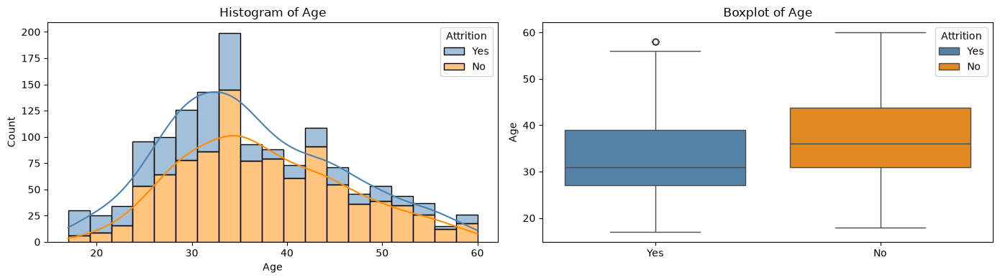

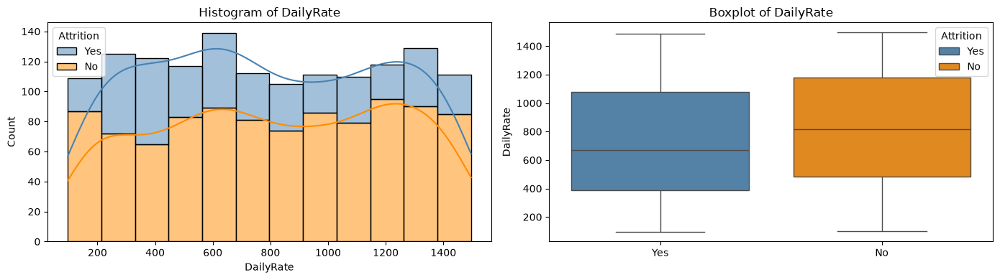

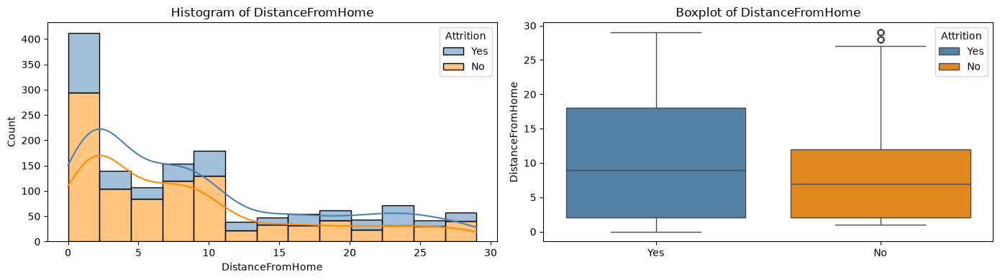

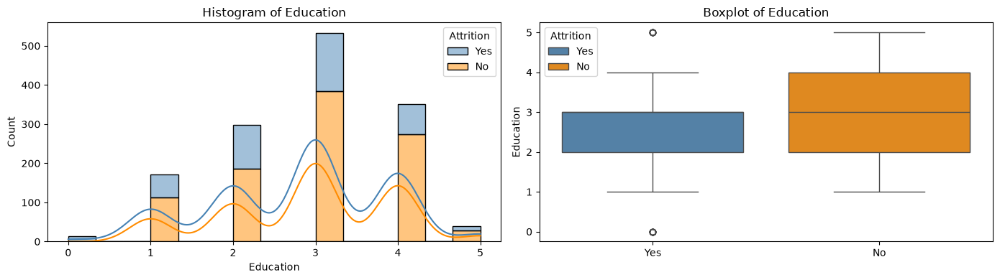

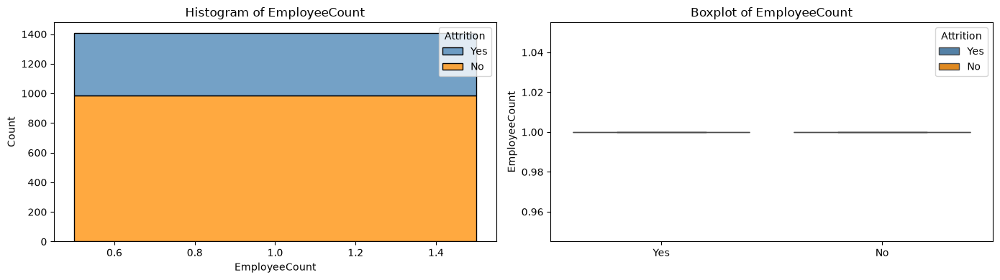

...

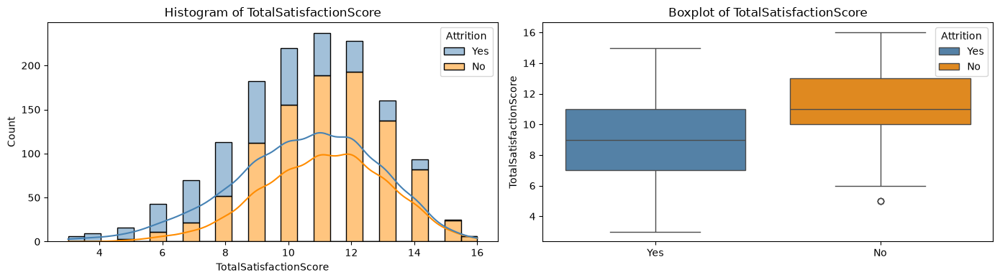

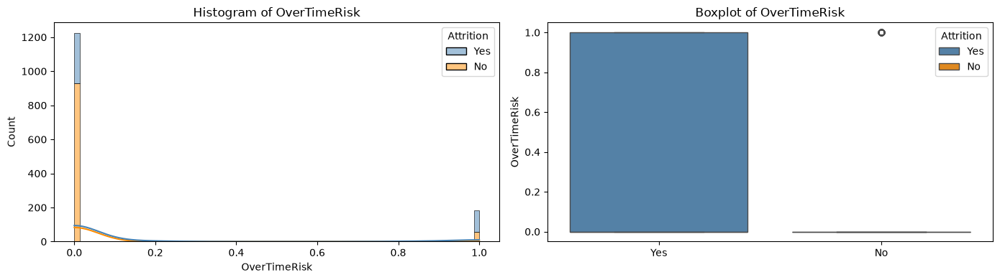

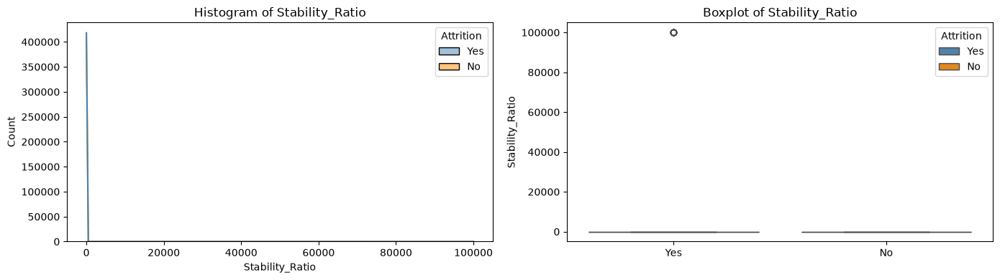

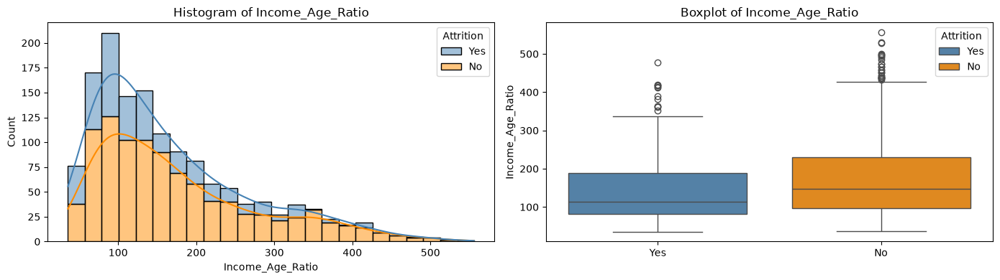

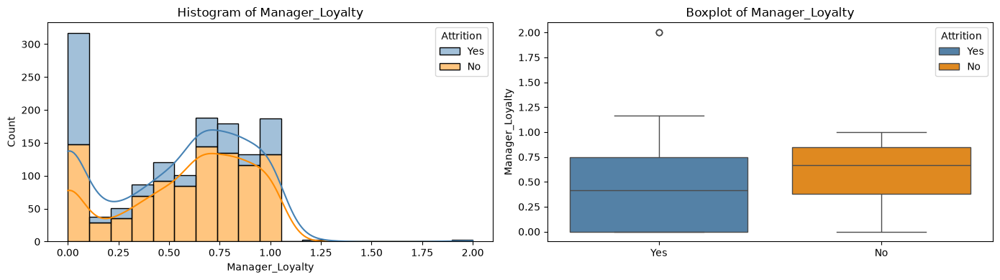

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Para cada atributo numérico: histograma empilhado por Attrition (com KDE)
# à esquerda e boxplot por Attrition à direita, no mesmo padrão de referência.
hue_order = ["Yes", "No"]
palette = {"Yes": "steelblue", "No": "darkorange"}

for col in num_attributes_fe:
    # KDE exige variância > 0. Colunas constantes (ex.: EmployeeCount,
    # StandardHours) quebrariam o gaussian_kde, então desligamos a curva.
    has_variance = df2[col].nunique(dropna=True) > 1

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    # Esquerda: histograma empilhado por Attrition com curva KDE.
    sns.histplot(
        data=df2,
        x=col,
        hue="Attrition",
        hue_order=hue_order,
        palette=palette,
        multiple="stack",
        kde=has_variance,
        ax=axes[0],
    )
    axes[0].set_title(f"Histogram of {col}")

    # Direita: boxplot por Attrition.
    sns.boxplot(
        data=df2,
        x="Attrition",
        y=col,
        hue="Attrition",
        hue_order=hue_order,
        palette=palette,
        legend=True,
        ax=axes[1],
    )
    axes[1].set_title(f"Boxplot of {col}")
    axes[1].set_xlabel("")

    plt.tight_layout()
    plt.show()


#### 6.1.1.1 KS Statistics

In [11]:
from scipy import stats

# KS Statistic (Kolmogorov-Smirnov)
age_no = df2.loc[df2['Attrition'] == 'No', 'Age']
age_yes = df2.loc[df2['Attrition'] == 'Yes', 'Age']

ks_stat, ks_p = stats.ks_2samp(age_no, age_yes)

print( f"KS Statistic: {ks_stat:.4f}, p-value: {ks_p:.4f}" )
print( f"Interpretacao: {'Descriminativo' if ks_stat > 0.2 else 'Fraco'}")

KS Statistic: 0.2679, p-value: 0.0000
Interpretacao: Descriminativo


#### 6.1.1.2 Overleap coefficient


Overlap Coefficient para Age: 0.7631
Interpretacao: Fraco


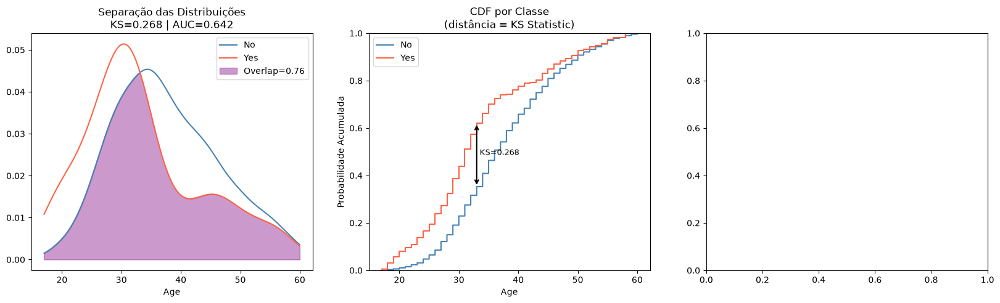

In [12]:
import numpy as np
# Overlap Coefficient
from scipy.stats import gaussian_kde
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder

kde_no = gaussian_kde(age_no)
kde_yes = gaussian_kde(age_yes)

x_range = np.linspace(df2['Age'].min(), df2['Age'].max(), 1000)
overlap  = np.trapezoid(np.minimum(kde_no(x_range), kde_yes(x_range)), x_range)
print( f"\nOverlap Coefficient para Age: {overlap:.4f}" )
print( f"Interpretacao: {'Descriminativo' if overlap < 0.7 else 'Fraco'}" )

# AUC univariado de Age (necessário para o título do Plot 1).
# Calculado aqui para tornar a célula autossuficiente; a seção 6.1.4
# recalcula o AUC para a curva ROC.
_y_age = LabelEncoder().fit_transform(df2['Attrition'])
_auc_model = LogisticRegression(max_iter=500).fit(df2[['Age']], _y_age)
auc = roc_auc_score(_y_age, _auc_model.predict_proba(df2[['Age']])[:, 1])
auc = max(auc, 1 - auc)  # garante AUC >= 0.5

# ================================================
# Plot 1 — KDE com área de overlap destacada
# ================================================
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
x_range      = np.linspace(df2['Age'].min(), df2['Age'].max(), 1000)
kde_no_vals  = kde_no(x_range)
kde_yes_vals = kde_yes(x_range)

axes[0].plot(x_range, kde_no_vals,  label='No',  color='steelblue')
axes[0].plot(x_range, kde_yes_vals, label='Yes', color='tomato')
axes[0].fill_between(x_range, np.minimum(kde_no_vals, kde_yes_vals),
                     alpha=0.4, color='purple', label=f'Overlap={overlap:.2f}')
axes[0].set_title(f'Separação das Distribuições\nKS={ks_stat:.3f} | AUC={auc:.3f}')
axes[0].set_xlabel('Age')
axes[0].legend()

# ================================================
# Plot 2 — CDF por classe (KS Statistic)
# ================================================
axes[1].ecdf(age_no,  label='No',  color='steelblue')
axes[1].ecdf(age_yes, label='Yes', color='tomato')

# Marca o ponto de máxima distância (KS)
all_ages   = np.sort(np.concatenate([age_no, age_yes]))
cdf_no     = np.searchsorted(np.sort(age_no),  all_ages, side='right') / len(age_no)
cdf_yes    = np.searchsorted(np.sort(age_yes), all_ages, side='right') / len(age_yes)
ks_idx     = np.argmax(np.abs(cdf_no - cdf_yes))
ks_x       = all_ages[ks_idx]

axes[1].annotate('', 
    xy=(ks_x, cdf_yes[ks_idx]), xytext=(ks_x, cdf_no[ks_idx]),
    arrowprops=dict(arrowstyle='<->', color='black', lw=1.5))
axes[1].text(ks_x + 0.5, (cdf_no[ks_idx] + cdf_yes[ks_idx]) / 2,
             f'KS={ks_stat:.3f}', fontsize=9, color='black')

axes[1].set_title('CDF por Classe\n(distância = KS Statistic)')
axes[1].set_xlabel('Age')
axes[1].set_ylabel('Probabilidade Acumulada')
axes[1].legend()

#### 6.1.1.4 AUC Univariate


AUC Univariado para Age: 0.6418
Interpretacao: Descriminativo


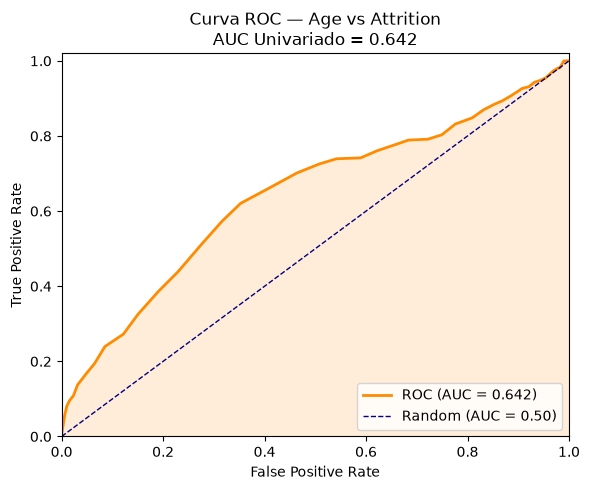

In [13]:
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve

# AUC Univariado
X = df2[['Age']]
y = LabelEncoder().fit_transform(df2['Attrition'])

model = LogisticRegression(max_iter=500)
model.fit(X, y)
y_prob = model.predict_proba(X)[:, 1]

auc = roc_auc_score(y, y_prob)
print(f"\nAUC Univariado para Age: {auc:.4f}")
print(f"Interpretacao: {'Descriminativo' if auc > 0.55 else 'Fraco'}")

# ================================================
# Curva ROC (AUC Univariado) — figura própria desta célula
# ================================================
fpr, tpr, _ = roc_curve(y, y_prob)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC (AUC = {auc:.3f})')
ax.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random (AUC = 0.50)')
ax.fill_between(fpr, tpr, alpha=0.15, color='darkorange')

ax.set_title('Curva ROC — Age vs Attrition\n'
             f'AUC Univariado = {auc:.3f}')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.legend(loc='lower right')
ax.set_xlim([0, 1])
ax.set_ylim([0, 1.02])

plt.tight_layout()
plt.show()

#### 6.1.1.5 Outlier

In [14]:
# --- 3. Outliers (IQR method) ---
# Define a série a analisar (Age é a coluna foco da seção 6.1).
series = df2['Age'].dropna()

Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
IQR     = Q3 - Q1
n_outliers = int(((series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)).sum())
pct_outliers = n_outliers / len(series) * 100

print(f"Outliers em Age (IQR): {n_outliers} ({pct_outliers:.2f}%)")
print(f"Limites: [{Q1 - 1.5 * IQR:.1f}, {Q3 + 1.5 * IQR:.1f}]")

Outliers em Age (IQR): 0 (0.00%)
Limites: [10.5, 62.5]


#### 6.1.1.6 Função final

In [15]:
import numpy as np
from scipy import stats
from scipy.stats import gaussian_kde
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# ================================================
# Univariate Analysis: Separation + Outliers
# ================================================

y = LabelEncoder().fit_transform(df2['Attrition'])   # No=0, Yes=1
num_cols = df2.select_dtypes(include=[np.number]).columns.tolist()

results = []

for col in num_cols:
    series    = df2[col].dropna()
    group_no  = df2.loc[df2['Attrition'] == 'No',  col].dropna()
    group_yes = df2.loc[df2['Attrition'] == 'Yes', col].dropna()

    # --- 1. Distribuição ---
    mean_no,  std_no  = group_no.mean(),  group_no.std()
    mean_yes, std_yes = group_yes.mean(), group_yes.std()

    # --- 2. Separação entre classes ---
    # KS Statistic
    ks_stat, ks_p = stats.ks_2samp(group_no, group_yes)

    # AUC Univariado
    X_col = df2[[col]].fillna(df2[col].median())
    try:
        model = LogisticRegression(max_iter=500).fit(X_col, y)
        auc   = roc_auc_score(y, model.predict_proba(X_col)[:, 1])
        auc   = max(auc, 1 - auc)   # garante AUC >= 0.5
    except Exception:
        auc = np.nan

    # Overlap Coefficient via KDE
    try:
        kde_no  = gaussian_kde(group_no)
        kde_yes = gaussian_kde(group_yes)
        x_range = np.linspace(series.min(), series.max(), 500)
        overlap = float(np.trapezoid(np.minimum(kde_no(x_range), kde_yes(x_range)), x_range))
    except Exception:
        overlap = np.nan

    # --- 3. Outliers (IQR method) ---
    Q1, Q3 = series.quantile(0.25), series.quantile(0.75)
    IQR     = Q3 - Q1
    n_outliers = int(((series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)).sum())
    pct_outliers = n_outliers / len(series) * 100

    results.append({
        'Feature'        : col,
        'Mean (No)'      : round(mean_no, 2),
        'Mean (Yes)'     : round(mean_yes, 2),
        'Std (No)'       : round(std_no, 2),
        'Std (Yes)'      : round(std_yes, 2),
        'KS Stat'        : round(ks_stat, 4),
        'KS p-value'     : round(ks_p, 4),
        'AUC Univariado' : round(auc, 4),
        'Overlap Coef.'  : round(overlap, 4),
        'N Outliers'     : n_outliers,
        '% Outliers'     : round(pct_outliers, 2),
    })

df_analysis = pd.DataFrame(results).sort_values('AUC Univariado', ascending=False)

# --- Classificação automática por poder discriminativo ---
def classify(row):
    if row['AUC Univariado'] >= 0.65:
        return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55:
        return '🟡 Média'
    else:
        return '🔴 Baixa'

df_analysis['Discriminação'] = df_analysis.apply(classify, axis=1)

print("=" * 80)
print("UNIVARIATE ANALYSIS SUMMARY")
print("=" * 80)
df_analysis


UNIVARIATE ANALYSIS SUMMARY


,Feature,Mean (No),Mean (Yes),Std (No),Std (Yes),KS Stat,KS p-value,AUC Univariado,Overlap Coef.,N Outliers,% Outliers,Discriminação
32,TotalSatisfactionScore,11.15,9.08,1.96,2.41,0.3635,0.0000,0.7430,0.6429,15,1.07,🟢 Alta
9,JobLevel,2.15,1.42,1.11,1.10,0.3078,0.0000,0.6857,0.6963,149,10.58,🟢 Alta
8,JobInvolvement,2.77,2.18,0.70,0.90,0.3091,0.0000,0.6841,0.6338,17,1.21,🟢 Alta
18,StockOptionLevel,0.86,0.42,0.83,0.80,0.3529,0.0000,0.6670,0.4449,75,5.33,🟢 Alta
19,TotalWorkingYears,11.74,8.02,7.77,7.62,0.2576,0.0000,0.6651,0.7383,69,4.90,🟢 Alta
22,YearsAtCompany,7.37,5.02,6.26,6.37,0.2667,0.0000,0.6629,0.7184,90,6.39,🟢 Alta
26,CareerStability,4.48,3.07,4.27,4.12,0.2721,0.0000,0.6613,0.7453,77,5.47,🟢 Alta
25,YearsWithCurrManager,4.36,2.64,3.61,3.13,0.2745,0.0000,0.6591,0.6815,7,0.50,🟢 Alta
23,YearsInCurrentRole,4.44,2.71,3.64,3.14,0.2531,0.0000,0.6583,0.6917,6,0.43,🟢 Alta
10,JobSatisfaction,2.82,2.18,1.09,1.19,0.2165,0.0000,0.6479,0.6956,0,0.00,🟡 Média


In [16]:
# Lista das variáveis que tem Baixa discriminação
low_discrimination_vars = df_analysis[df_analysis['Discriminação'] == '🔴 Baixa']['Feature'].tolist()

#### 6.1.2 Categorical univariate

##### 6.1.2.1 Chi-Square

In [17]:
from scipy.stats import chi2_contingency

# --- Cramér's V ---
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# --- Análise categórica ---
y = LabelEncoder().fit_transform(df2['Attrition'])
cat_cols = df2.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']

y = LabelEncoder().fit_transform(df2['Attrition'])  # No=0, Yes=1
cat_cols = df2.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']

results_cat = []

for col in cat_cols:
    series = df2[col].fillna('Missing')

    # --- 1. Chi-Square ---
    contingency = pd.crosstab(series, df2['Attrition'])
    chi2, p_value, _, _ = chi2_contingency(contingency)

##### 6.1.2.2 Kramer V

In [18]:
 # --- 2. Cramér's V (Effect Size) ---
cv = cramers_v(series, df2['Attrition'])

##### 6.1.2.3 AUC 

In [19]:
# --- 3. AUC Univariado ---
X_enc = LabelEncoder().fit_transform(series).reshape(-1, 1)
try:
    model = LogisticRegression(max_iter=300).fit(X_enc, y)
    auc   = roc_auc_score(y, model.predict_proba(X_enc)[:, 1])
    auc   = max(auc, 1 - auc)
except Exception:
    auc = np.nan

##### 6.1.2.4 Resultado final com todos

In [20]:
from scipy.stats import chi2_contingency

# --- Cramér's V ---
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# --- Análise categórica ---
y = LabelEncoder().fit_transform(df2['Attrition'])
cat_cols = df2.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']

y = LabelEncoder().fit_transform(df2['Attrition'])  # No=0, Yes=1
cat_cols = df2.select_dtypes(include=['object']).columns.tolist()
cat_cols = [c for c in cat_cols if c != 'Attrition']

results_cat = []

for col in cat_cols:
    series = df2[col].fillna('Missing')

    # --- 1. Chi-Square ---
    contingency = pd.crosstab(series, df2['Attrition'])
    chi2, p_value, _, _ = chi2_contingency(contingency)

    # --- 2. Cramér's V (Effect Size) ---
    cv = cramers_v(series, df2['Attrition'])

    # --- 3. AUC Univariado ---
    X_enc = LabelEncoder().fit_transform(series).reshape(-1, 1)
    try:
        model = LogisticRegression(max_iter=300).fit(X_enc, y)
        auc   = roc_auc_score(y, model.predict_proba(X_enc)[:, 1])
        auc   = max(auc, 1 - auc)
    except Exception:
        auc = np.nan

    # --- 4. Taxa de Attrition por categoria ---
    attrition_rate = (
        df2.groupby(col)['Attrition']
        .apply(lambda x: (x == 'Yes').mean())
        .to_dict()
    )

    results_cat.append({
        'Feature'            : col,
        'Chi2'               : round(chi2, 2),
        'p-value'            : round(p_value, 4),
        "Cramér's V"         : round(cv, 4),
        'AUC Univariado'     : round(auc, 4),
        'Taxa Attrition/Cat' : {k: f"{v:.0%}" for k, v in attrition_rate.items()},
    })

def classify_cat(row):
    if row['AUC Univariado'] >= 0.65:  return '🟢 Alta'
    elif row['AUC Univariado'] >= 0.55: return '🟡 Média'
    else:                               return '🔴 Baixa'

df_cat_analysis = pd.DataFrame(results_cat).sort_values('AUC Univariado', ascending=False)
df_cat_analysis['Discriminação'] = df_cat_analysis.apply(classify_cat, axis=1)

print("=" * 70)
print("CATEGORICAL UNIVARIATE ANALYSIS")
print("=" * 70)
df_cat_analysis[['Feature', 'Chi2', 'p-value', "Cramér's V", 'AUC Univariado', 'Discriminação']]


CATEGORICAL UNIVARIATE ANALYSIS


,Feature,Chi2,p-value,Cramér's V,AUC Univariado,Discriminação
7,OverTime,123.20,0.0000,0.2947,0.6513,🟢 Alta
5,MaritalStatus,84.98,0.0000,0.2429,0.6369,🟡 Média
4,JobRole,131.46,0.0000,0.2962,0.5756,🟡 Média
1,Department,23.02,0.0000,0.1222,0.5503,🟡 Média
8,AgeGroup,55.76,0.0000,0.1955,0.5457,🔴 Baixa
0,BusinessTravel,48.24,0.0000,0.1813,0.5281,🔴 Baixa
3,Gender,2.10,0.1471,0.0280,0.5214,🔴 Baixa
2,EducationField,29.71,0.0000,0.1325,0.5068,🔴 Baixa
6,Over18,0.00,1.0000,NaN,0.5000,🔴 Baixa


- Aqui o AUC é mais representativo que as outras métricas

In [21]:
# Lista das variáveis categóricas que tem Baixa discriminação
low_discrimination_cat_vars = df_cat_analysis[df_cat_analysis['Discriminação'] == '🔴 Baixa']['Feature'].tolist()

##### 6.1.2.5 Gráfico

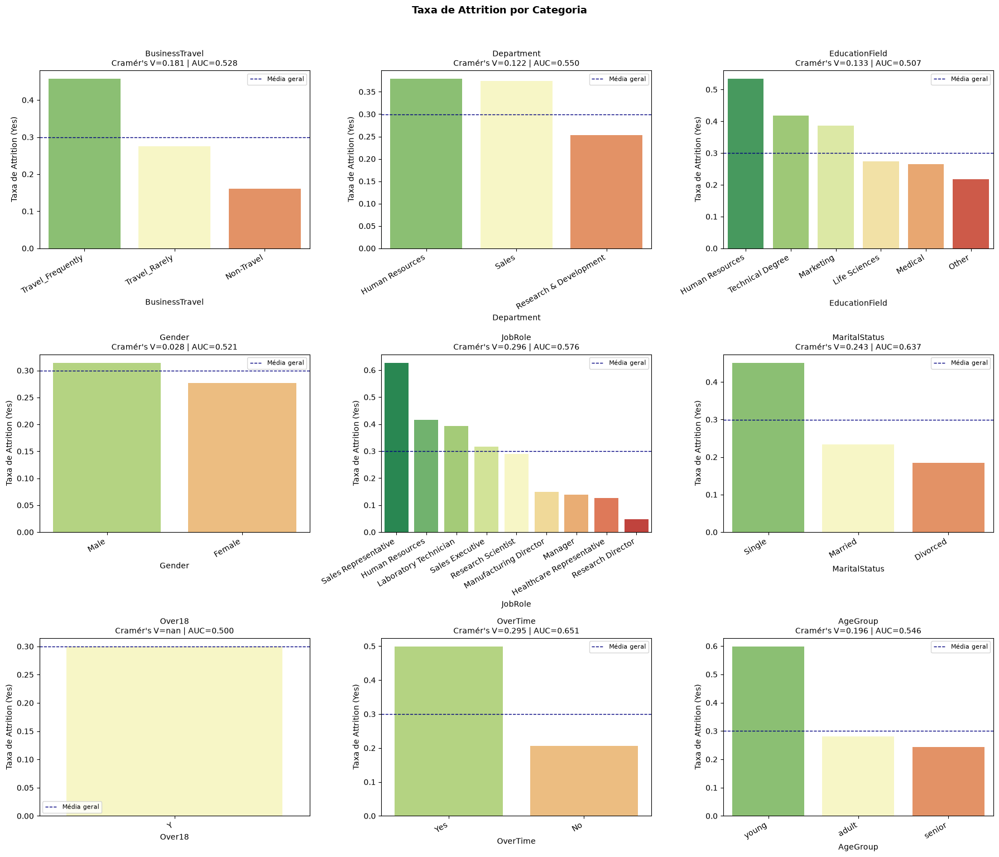

In [22]:
import math

max_cols = 3
n_plots  = len(cat_cols)
n_cols   = min(n_plots, max_cols)
n_rows   = math.ceil(n_plots / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = np.array(axes).flatten()   # garante sempre 1D mesmo com 1 linha

for i, col in enumerate(cat_cols):
    attrition_rate = (
        df2.groupby(col)['Attrition']
        .apply(lambda x: (x == 'Yes').mean())
        .sort_values(ascending=False)
        .reset_index()
    )
    attrition_rate.columns = [col, 'Attrition Rate']

    row = df_cat_analysis[df_cat_analysis['Feature'] == col].iloc[0]
    cv  = row["Cramér's V"]
    auc = row['AUC Univariado']

    sns.barplot(data=attrition_rate, x=col, y='Attrition Rate',
                ax=axes[i], palette='RdYlGn_r')
    axes[i].set_title(f"{col}\nCramér's V={cv:.3f} | AUC={auc:.3f}", fontsize=10)
    axes[i].set_ylabel('Taxa de Attrition (Yes)')
    axes[i].set_xticklabels(axes[i].get_xticklabels(), rotation=30, ha='right')
    axes[i].axhline(df2['Attrition'].eq('Yes').mean(),
                    color='navy', linestyle='--', linewidth=1, label='Média geral')
    axes[i].legend(fontsize=8)

# Oculta eixos vazios (quando n_plots não preenche o grid)
for j in range(n_plots, len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Taxa de Attrition por Categoria', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 6.2 Bivariate analysis

#### 6.2.1 Numerical bivariate analysis

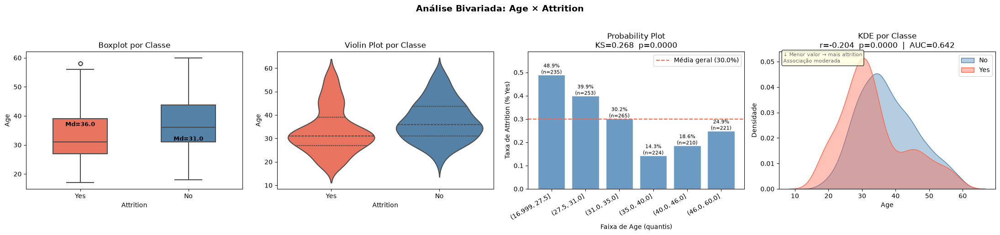

─────────────────────────────────────────────────────────────────
  Age
  KS=0.2679  p=0.0000  |  r=-0.2036  |  AUC=0.6418  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



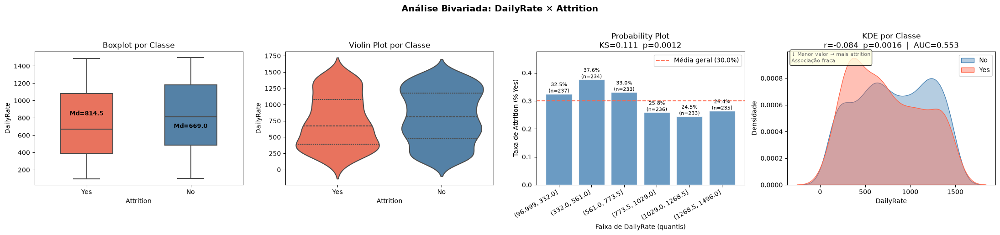

─────────────────────────────────────────────────────────────────
  DailyRate
  KS=0.1112  p=0.0012  |  r=-0.0841  |  AUC=0.5530  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



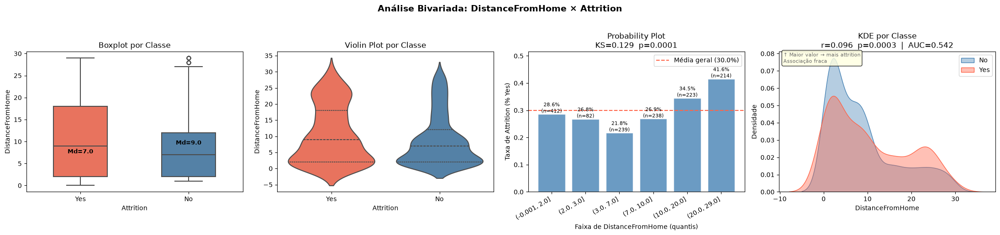

─────────────────────────────────────────────────────────────────
  DistanceFromHome
  KS=0.1286  p=0.0001  |  r=0.0960  |  AUC=0.5425  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



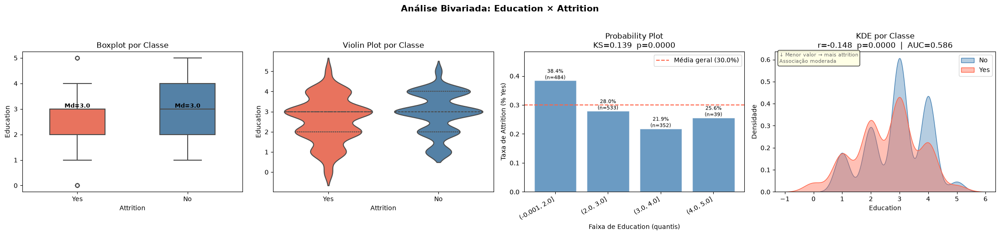

─────────────────────────────────────────────────────────────────
  Education
  KS=0.1385  p=0.0000  |  r=-0.1479  |  AUC=0.5863  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────

[skip] EmployeeCount: coluna constante, sem análise bivariada.


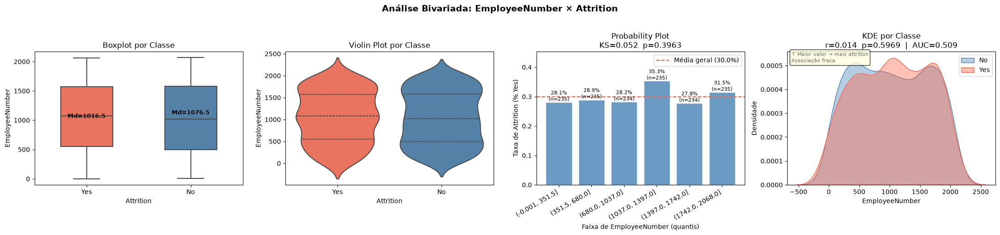

─────────────────────────────────────────────────────────────────
  EmployeeNumber
  KS=0.0515  p=0.3963  |  r=0.0141  |  AUC=0.5090  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



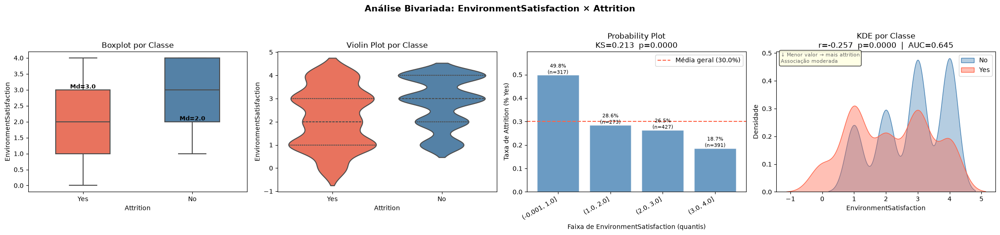

─────────────────────────────────────────────────────────────────
  EnvironmentSatisfaction
  KS=0.2131  p=0.0000  |  r=-0.2572  |  AUC=0.6451  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



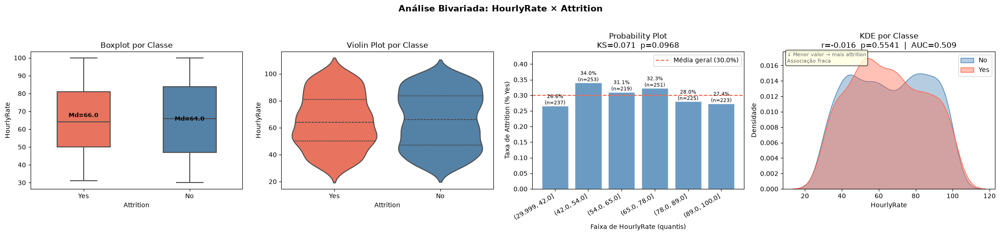

─────────────────────────────────────────────────────────────────
  HourlyRate
  KS=0.0709  p=0.0968  |  r=-0.0158  |  AUC=0.5094  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



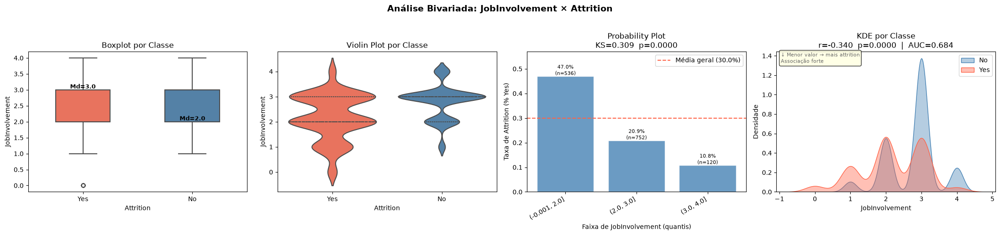

─────────────────────────────────────────────────────────────────
  JobInvolvement
  KS=0.3091  p=0.0000  |  r=-0.3395  |  AUC=0.6841  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



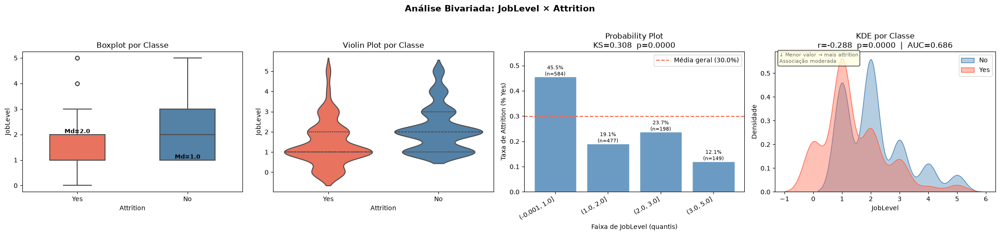

─────────────────────────────────────────────────────────────────
  JobLevel
  KS=0.3078  p=0.0000  |  r=-0.2879  |  AUC=0.6857  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



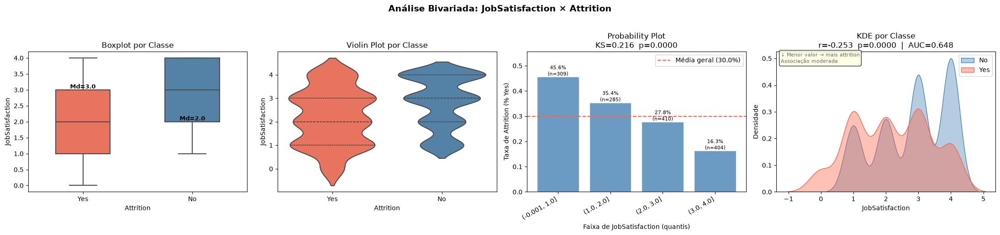

─────────────────────────────────────────────────────────────────
  JobSatisfaction
  KS=0.2165  p=0.0000  |  r=-0.2531  |  AUC=0.6479  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



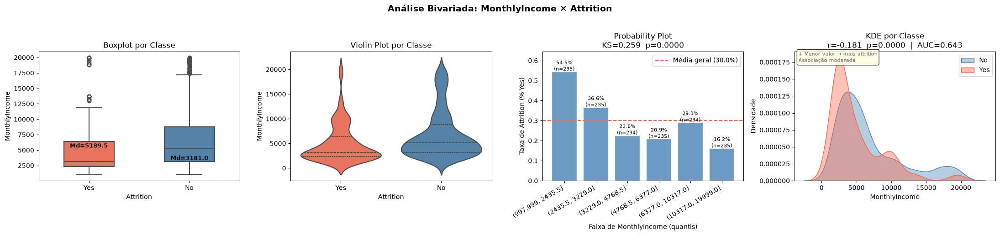

─────────────────────────────────────────────────────────────────
  MonthlyIncome
  KS=0.2587  p=0.0000  |  r=-0.1812  |  AUC=0.6431  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



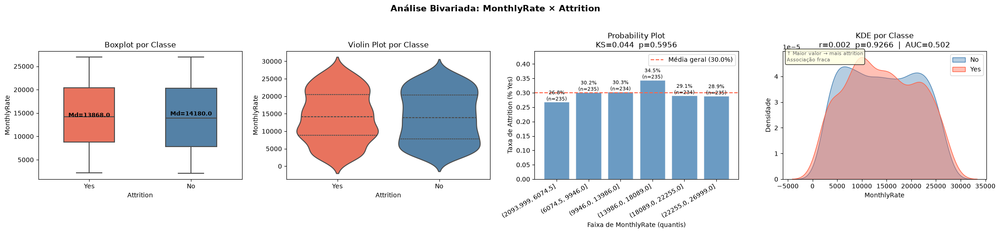

─────────────────────────────────────────────────────────────────
  MonthlyRate
  KS=0.0440  p=0.5956  |  r=0.0025  |  AUC=0.5018  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



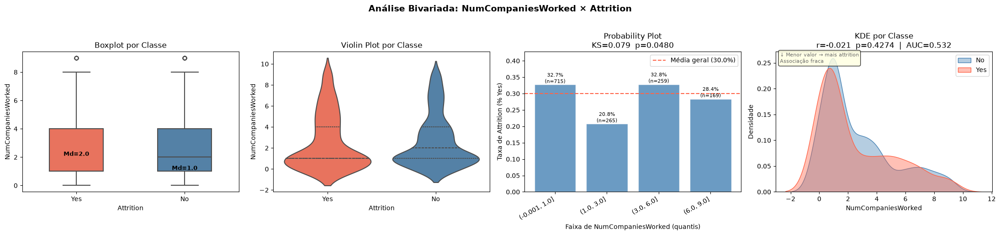

─────────────────────────────────────────────────────────────────
  NumCompaniesWorked
  KS=0.0787  p=0.0480  |  r=-0.0212  |  AUC=0.5323  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



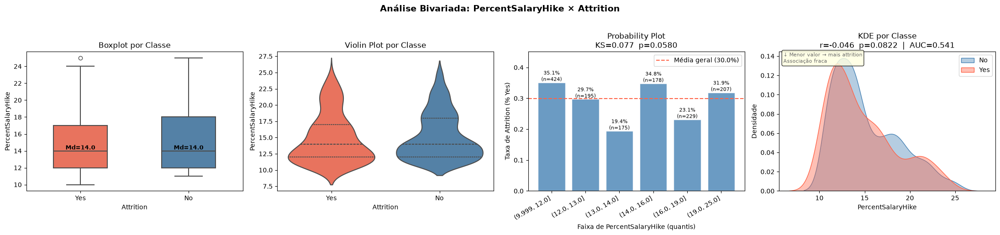

─────────────────────────────────────────────────────────────────
  PercentSalaryHike
  KS=0.0767  p=0.0580  |  r=-0.0463  |  AUC=0.5408  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



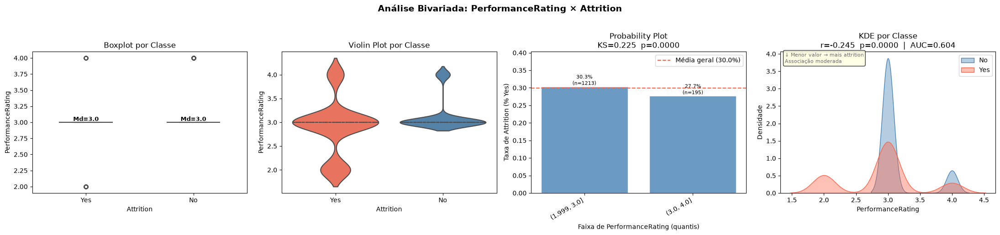

─────────────────────────────────────────────────────────────────
  PerformanceRating
  KS=0.2251  p=0.0000  |  r=-0.2455  |  AUC=0.6040  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



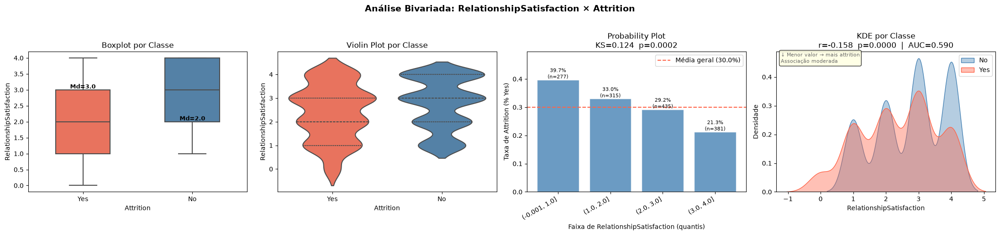

─────────────────────────────────────────────────────────────────
  RelationshipSatisfaction
  KS=0.1237  p=0.0002  |  r=-0.1584  |  AUC=0.5895  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────

[skip] StandardHours: coluna constante, sem análise bivariada.


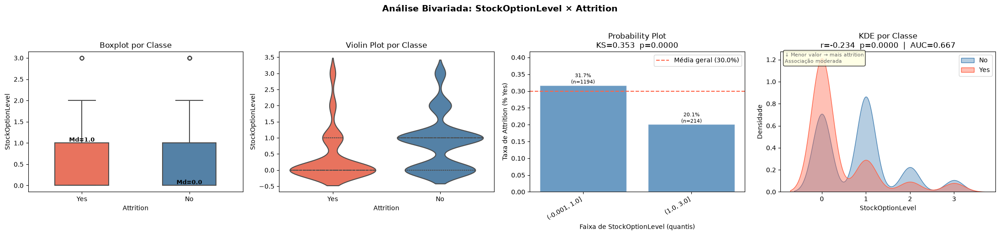

─────────────────────────────────────────────────────────────────
  StockOptionLevel
  KS=0.3529  p=0.0000  |  r=-0.2344  |  AUC=0.6670  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



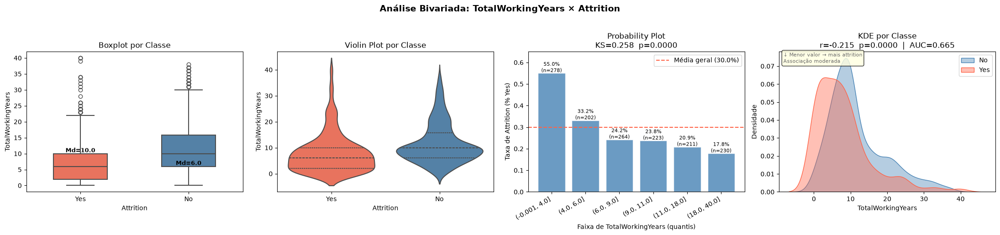

─────────────────────────────────────────────────────────────────
  TotalWorkingYears
  KS=0.2576  p=0.0000  |  r=-0.2153  |  AUC=0.6651  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



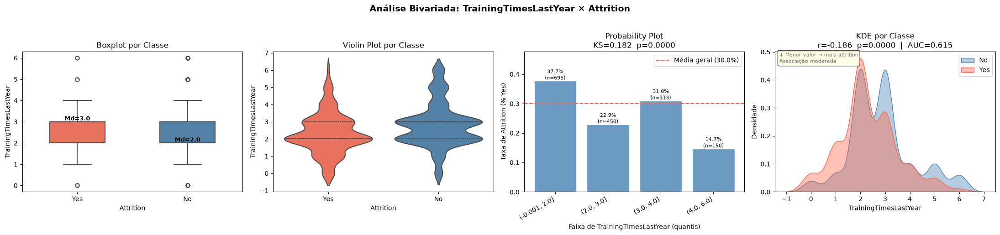

─────────────────────────────────────────────────────────────────
  TrainingTimesLastYear
  KS=0.1817  p=0.0000  |  r=-0.1861  |  AUC=0.6148  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



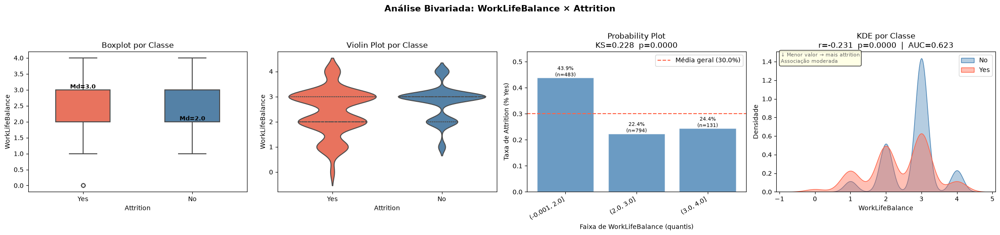

─────────────────────────────────────────────────────────────────
  WorkLifeBalance
  KS=0.2275  p=0.0000  |  r=-0.2308  |  AUC=0.6227  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



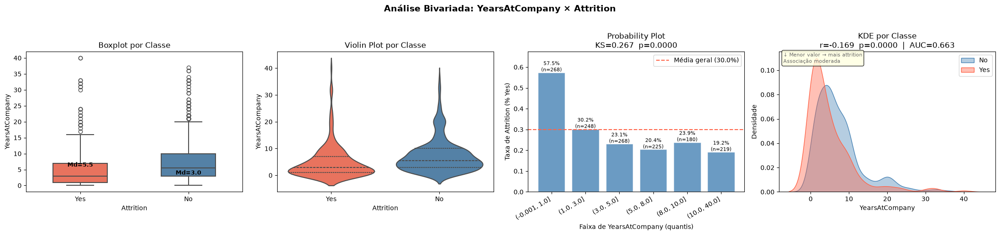

─────────────────────────────────────────────────────────────────
  YearsAtCompany
  KS=0.2667  p=0.0000  |  r=-0.1688  |  AUC=0.6629  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



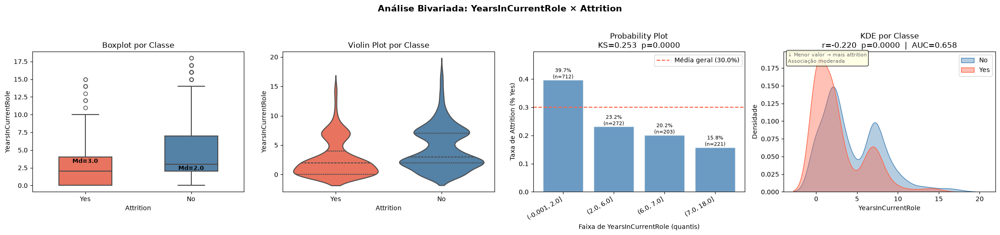

─────────────────────────────────────────────────────────────────
  YearsInCurrentRole
  KS=0.2531  p=0.0000  |  r=-0.2204  |  AUC=0.6583  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



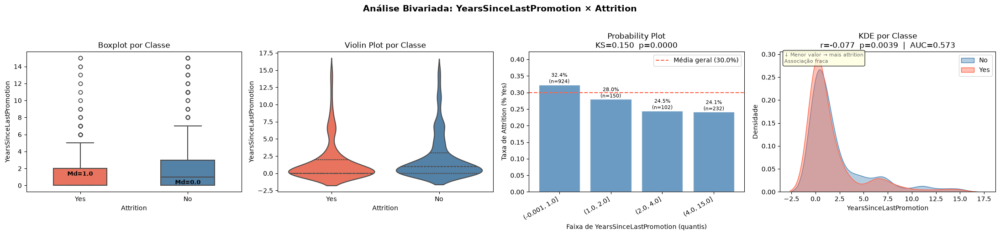

─────────────────────────────────────────────────────────────────
  YearsSinceLastPromotion
  KS=0.1501  p=0.0000  |  r=-0.0769  |  AUC=0.5729  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



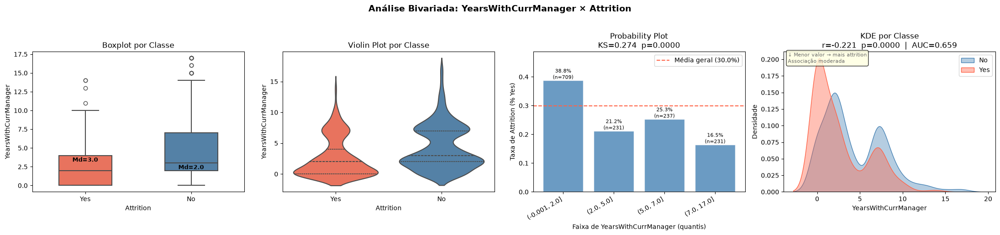

─────────────────────────────────────────────────────────────────
  YearsWithCurrManager
  KS=0.2745  p=0.0000  |  r=-0.2212  |  AUC=0.6591  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



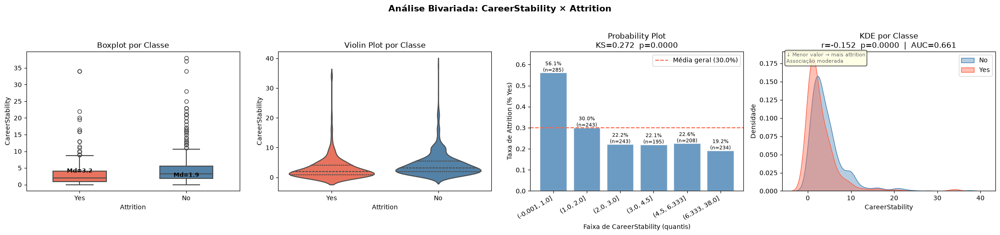

─────────────────────────────────────────────────────────────────
  CareerStability
  KS=0.2721  p=0.0000  |  r=-0.1517  |  AUC=0.6613  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



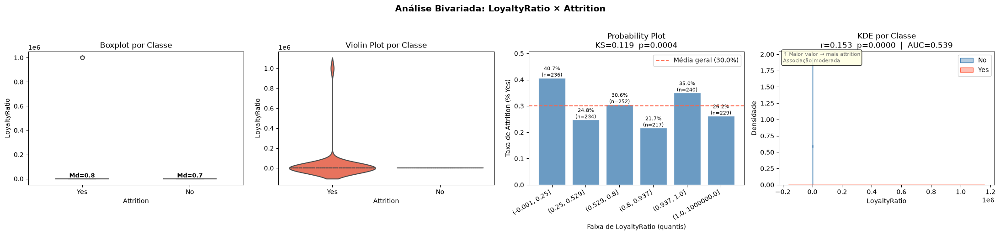

─────────────────────────────────────────────────────────────────
  LoyaltyRatio
  KS=0.1189  p=0.0004  |  r=0.1532  |  AUC=0.5389  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



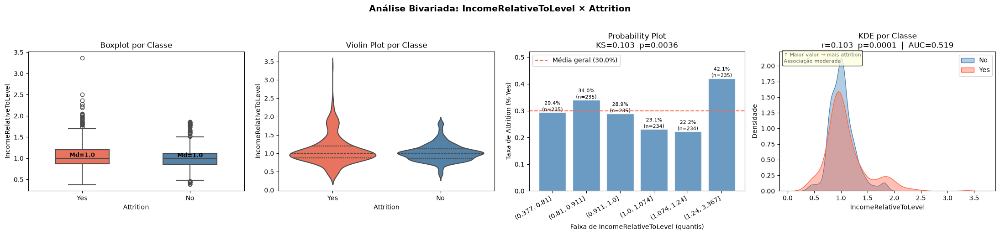

─────────────────────────────────────────────────────────────────
  IncomeRelativeToLevel
  KS=0.1027  p=0.0036  |  r=0.1027  |  AUC=0.5194  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



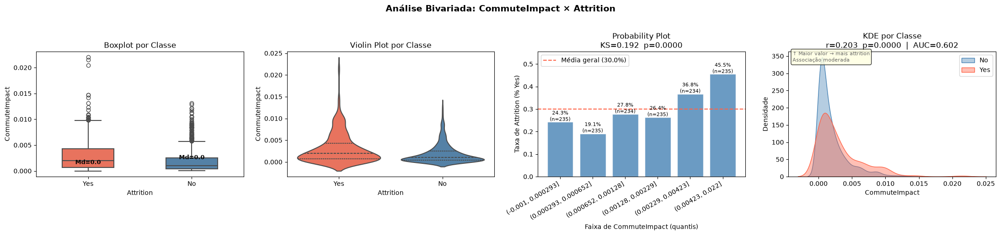

─────────────────────────────────────────────────────────────────
  CommuteImpact
  KS=0.1921  p=0.0000  |  r=0.2035  |  AUC=0.6018  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



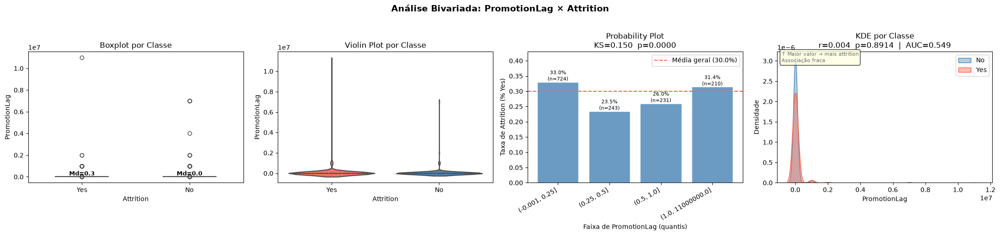

─────────────────────────────────────────────────────────────────
  PromotionLag
  KS=0.1501  p=0.0000  |  r=0.0036  |  AUC=0.5486  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



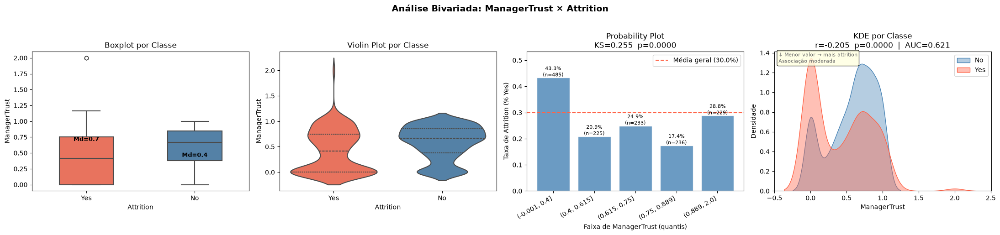

─────────────────────────────────────────────────────────────────
  ManagerTrust
  KS=0.2545  p=0.0000  |  r=-0.2045  |  AUC=0.6209  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



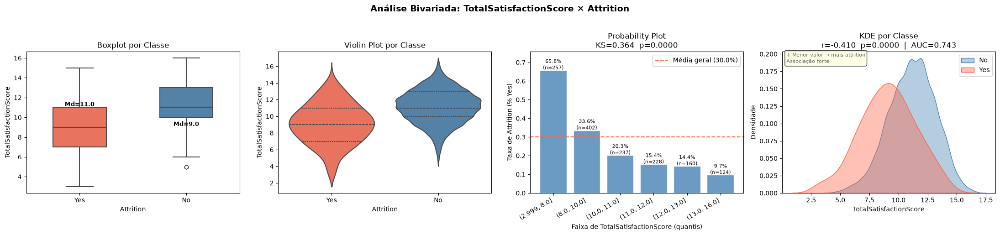

─────────────────────────────────────────────────────────────────
  TotalSatisfactionScore
  KS=0.3635  p=0.0000  |  r=-0.4103  |  AUC=0.7430  |  Discriminação: 🟢 Alta
─────────────────────────────────────────────────────────────────



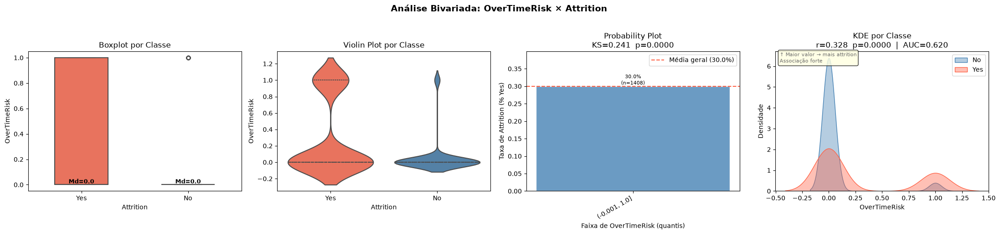

─────────────────────────────────────────────────────────────────
  OverTimeRisk
  KS=0.2408  p=0.0000  |  r=0.3280  |  AUC=0.6204  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



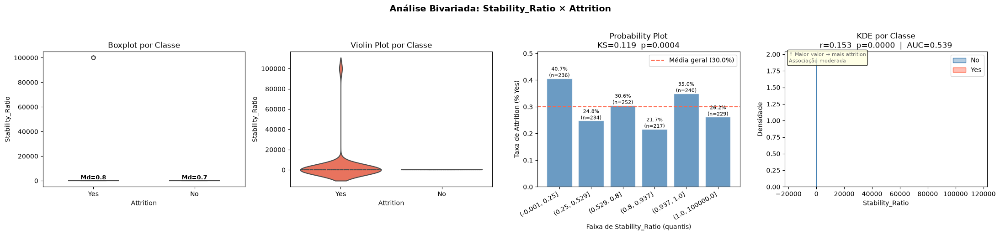

─────────────────────────────────────────────────────────────────
  Stability_Ratio
  KS=0.1189  p=0.0004  |  r=0.1532  |  AUC=0.5389  |  Discriminação: 🔴 Baixa
─────────────────────────────────────────────────────────────────



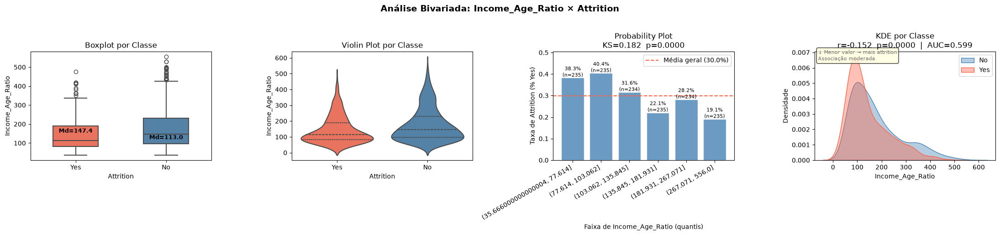

─────────────────────────────────────────────────────────────────
  Income_Age_Ratio
  KS=0.1817  p=0.0000  |  r=-0.1524  |  AUC=0.5988  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



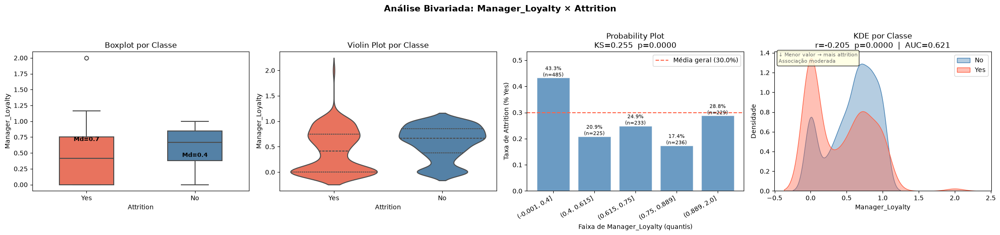

─────────────────────────────────────────────────────────────────
  Manager_Loyalty
  KS=0.2545  p=0.0000  |  r=-0.2045  |  AUC=0.6209  |  Discriminação: 🟡 Média
─────────────────────────────────────────────────────────────────



In [23]:
from scipy.stats import pointbiserialr

col_target = 'Attrition'
y_binary   = (df2[col_target] == 'Yes').astype(int)
num_cols   = df2.select_dtypes(include=[np.number]).columns.tolist()

for col in num_cols:
    # Pula colunas constantes (ex.: EmployeeCount, StandardHours): sem
    # variância não há faixas (qcut/cut) nem correlação válidas.
    if df2[col].nunique(dropna=True) <= 1:
        print(f"[skip] {col}: coluna constante, sem análise bivariada.")
        continue
    g_no  = df2.loc[df2[col_target] == 'No',  col].dropna()
    g_yes = df2.loc[df2[col_target] == 'Yes', col].dropna()

    # --- Métricas ---
    ks_stat, ks_p = stats.ks_2samp(g_no, g_yes)
    r_pb,    p_pb = pointbiserialr(y_binary, df2[col].fillna(df2[col].median()))

    X_col = df2[[col]].fillna(df2[col].median())
    model = LogisticRegression(max_iter=500).fit(X_col, y_binary)
    auc   = roc_auc_score(y_binary, model.predict_proba(X_col)[:, 1])
    auc   = max(auc, 1 - auc)

    # --- Probability Plot: faixas por quantil ---
    df_prob        = df2[[col, col_target]].copy()
    df_prob['y']   = y_binary
    taxa_geral     = y_binary.mean()

    try:
        df_prob['faixa'] = pd.qcut(df_prob[col], q=6, duplicates='drop')
    except ValueError:
        df_prob['faixa'] = pd.cut(df_prob[col], bins=6)

    prob_by_faixa = (
        df_prob.groupby('faixa', observed=True)['y']
        .agg(['mean', 'count'])
        .reset_index()
    )
    prob_by_faixa.columns = ['Faixa', 'Taxa Attrition', 'N']
    prob_by_faixa['Faixa'] = prob_by_faixa['Faixa'].astype(str)

    # --- Plots ---
    fig, axes = plt.subplots(1, 4, figsize=(22, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {col_target}',
                 fontsize=14, fontweight='bold', y=1.02)

    # ── Plot 1: Boxplot por classe ────────────────────────────────────────
    sns.boxplot(data=df2, x=col_target, y=col, ax=axes[0],
                hue=col_target,
                palette={'No': 'steelblue', 'Yes': 'tomato'},
                width=0.5, linewidth=1.5, legend=False)

    for i, (group, label) in enumerate([(g_no, 'No'), (g_yes, 'Yes')]):
        med = group.median()
        axes[0].text(i, med, f'Md={med:.1f}',
                     ha='center', va='bottom',
                     fontsize=9, fontweight='bold', color='black')

    axes[0].set_title('Boxplot por Classe')
    axes[0].set_xlabel(col_target)
    axes[0].set_ylabel(col)

    # ── Plot 2: Violin por classe ─────────────────────────────────────────
    sns.violinplot(data=df2, x=col_target, y=col, ax=axes[1],
                   hue=col_target,
                   palette={'No': 'steelblue', 'Yes': 'tomato'},
                   inner='quartile', linewidth=1.5, legend=False)

    axes[1].set_title('Violin Plot por Classe')
    axes[1].set_xlabel(col_target)
    axes[1].set_ylabel(col)

    # ── Plot 3: Probability Plot ──────────────────────────────────────────
    bars = axes[2].bar(
        prob_by_faixa['Faixa'], prob_by_faixa['Taxa Attrition'],
        color='steelblue', alpha=0.8, edgecolor='white'
    )
    axes[2].axhline(taxa_geral, color='tomato', linestyle='--',
                    linewidth=1.5, label=f'Média geral ({taxa_geral:.1%})')

    for bar, (_, row_data) in zip(bars, prob_by_faixa.iterrows()):
        axes[2].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.005,
                     f"{row_data['Taxa Attrition']:.1%}\n(n={int(row_data['N'])})",
                     ha='center', fontsize=8, color='black')

    axes[2].set_title(f'Probability Plot\nKS={ks_stat:.3f}  p={ks_p:.4f}')
    axes[2].set_xlabel(f'Faixa de {col} (quantis)')
    axes[2].set_ylabel('Taxa de Attrition (% Yes)')
    axes[2].set_xticks(range(len(prob_by_faixa)))
    axes[2].set_xticklabels(prob_by_faixa['Faixa'], rotation=30, ha='right')
    _ymax = prob_by_faixa['Taxa Attrition'].max()
    axes[2].set_ylim(0, (_ymax + 0.1) if pd.notna(_ymax) else 1)
    axes[2].legend()

    # ── Plot 4: KDE por classe + correlação ponto-biserial ────────────────
    sns.kdeplot(g_no,  ax=axes[3], label='No',  fill=True, alpha=0.4, color='steelblue')
    sns.kdeplot(g_yes, ax=axes[3], label='Yes', fill=True, alpha=0.4, color='tomato')

    direction = '↑ Maior valor → mais attrition' if r_pb > 0 else '↓ Menor valor → mais attrition'
    strength  = 'forte' if abs(r_pb) > 0.3 else 'moderada' if abs(r_pb) > 0.1 else 'fraca'

    axes[3].set_title(f'KDE por Classe\nr={r_pb:.3f}  p={p_pb:.4f}  |  AUC={auc:.3f}')
    axes[3].set_xlabel(col)
    axes[3].set_ylabel('Densidade')
    axes[3].legend()
    axes[3].text(0.02, 0.92, f'{direction}\nAssociação {strength}',
                 transform=axes[3].transAxes, fontsize=8, color='dimgray',
                 bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

    plt.tight_layout()
    plt.show()
    plt.close(fig)

    # --- Resumo textual ---
    discriminacao = '🟢 Alta' if auc >= 0.65 else '🟡 Média' if auc >= 0.55 else '🔴 Baixa'
    print(f"{'─'*65}")
    print(f"  {col}")
    print(f"  KS={ks_stat:.4f}  p={ks_p:.4f}  |  r={r_pb:.4f}  |  AUC={auc:.4f}  |  Discriminação: {discriminacao}")
    print(f"{'─'*65}\n")


- Gráfico 3 é a probabilidade de saídas para a classe analisada

#### 6.2.3 Categorical bivariate analysis

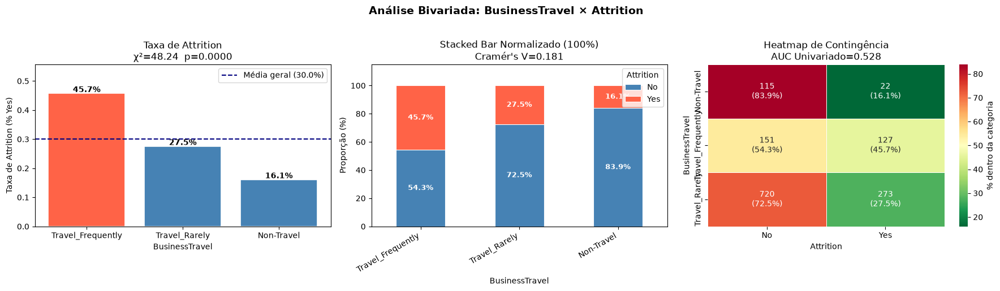

───────────────────────────────────────────────────────
  BusinessTravel
  χ²=48.24  p=0.0000  |  Cramér's V=0.1813  |  AUC=0.5281  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



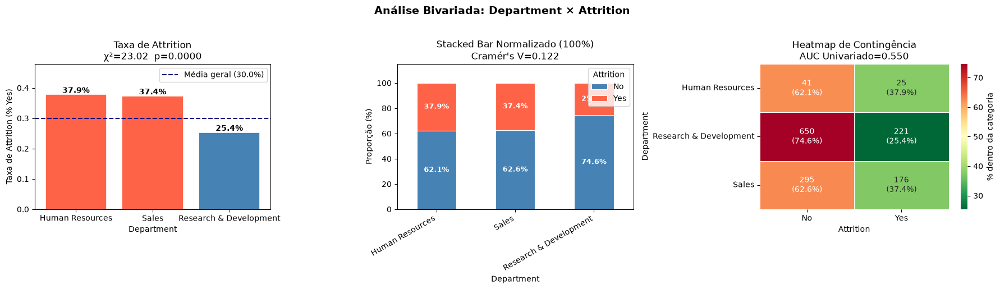

───────────────────────────────────────────────────────
  Department
  χ²=23.02  p=0.0000  |  Cramér's V=0.1222  |  AUC=0.5503  |  Discriminação: 🟡 Média
───────────────────────────────────────────────────────



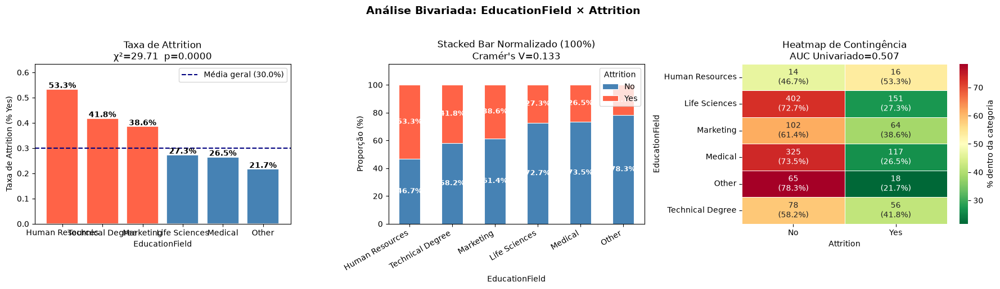

───────────────────────────────────────────────────────
  EducationField
  χ²=29.71  p=0.0000  |  Cramér's V=0.1325  |  AUC=0.5068  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



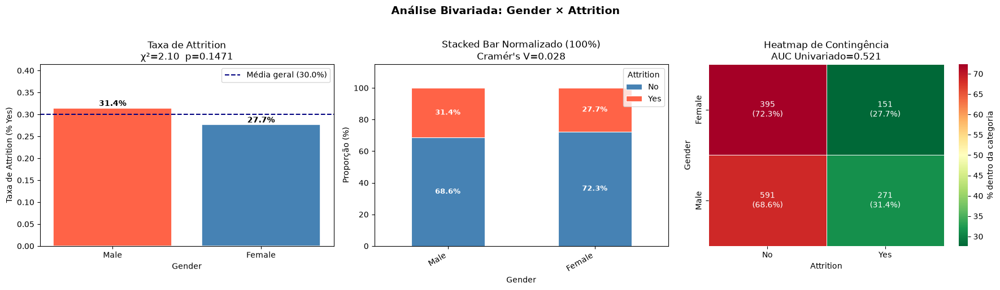

───────────────────────────────────────────────────────
  Gender
  χ²=2.10  p=0.1471  |  Cramér's V=0.0280  |  AUC=0.5214  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



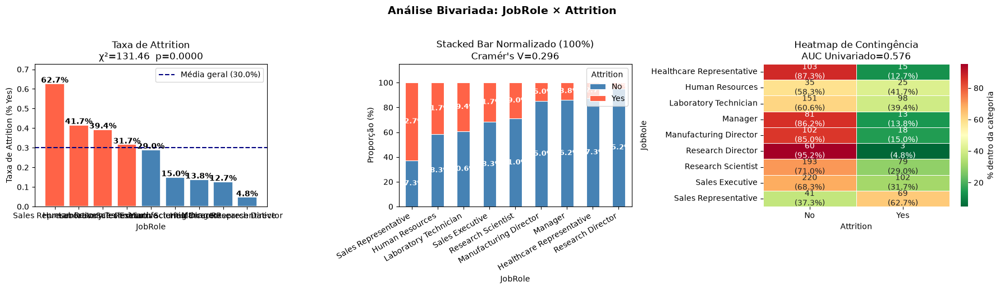

───────────────────────────────────────────────────────
  JobRole
  χ²=131.46  p=0.0000  |  Cramér's V=0.2962  |  AUC=0.5756  |  Discriminação: 🟡 Média
───────────────────────────────────────────────────────



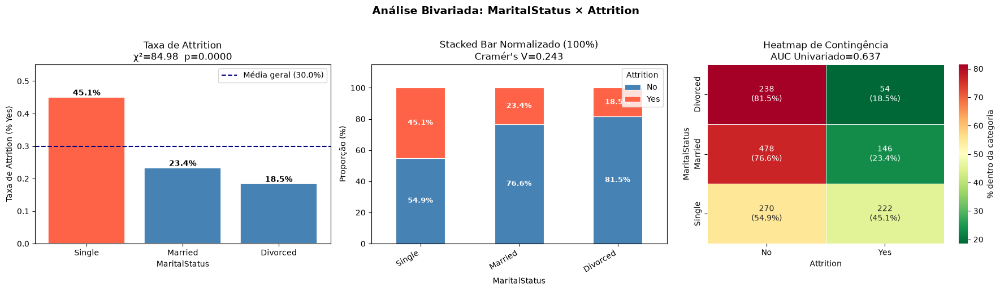

───────────────────────────────────────────────────────
  MaritalStatus
  χ²=84.98  p=0.0000  |  Cramér's V=0.2429  |  AUC=0.6369  |  Discriminação: 🟢 Alta
───────────────────────────────────────────────────────



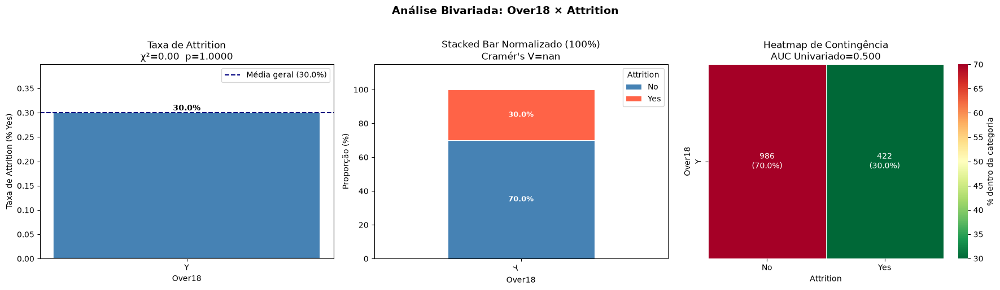

───────────────────────────────────────────────────────
  Over18
  χ²=0.00  p=1.0000  |  Cramér's V=nan  |  AUC=0.5000  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



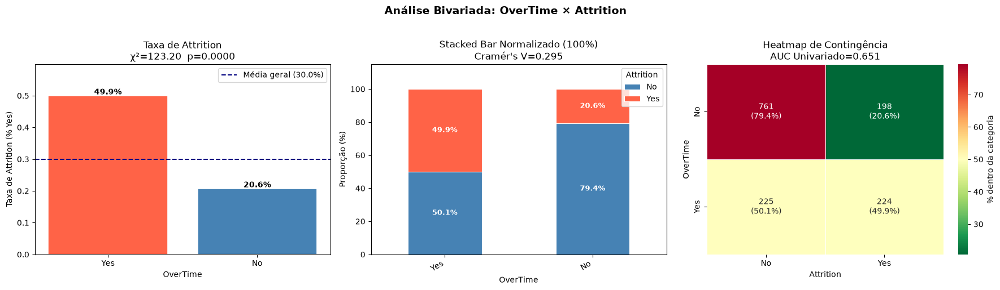

───────────────────────────────────────────────────────
  OverTime
  χ²=123.20  p=0.0000  |  Cramér's V=0.2947  |  AUC=0.6513  |  Discriminação: 🟢 Alta
───────────────────────────────────────────────────────



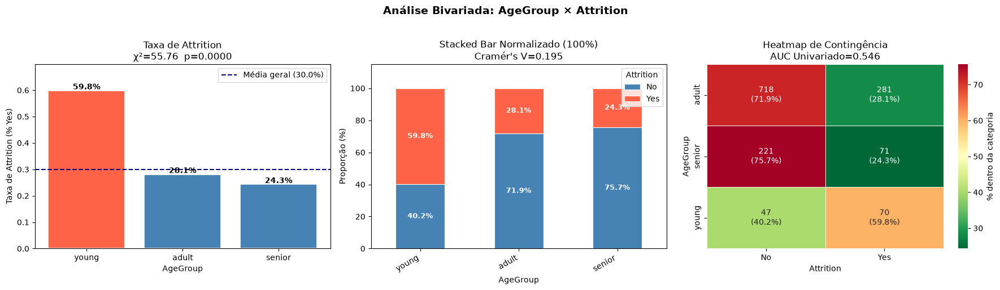

───────────────────────────────────────────────────────
  AgeGroup
  χ²=55.76  p=0.0000  |  Cramér's V=0.1955  |  AUC=0.5457  |  Discriminação: 🔴 Baixa
───────────────────────────────────────────────────────



In [24]:
import math

col_target = 'Attrition'
y_binary   = (df2[col_target] == 'Yes').astype(int)
cat_cols   = df2.select_dtypes(include=['object']).columns.tolist()
cat_cols   = [c for c in cat_cols if c != col_target]

for col in cat_cols:

    # --- Métricas ---
    contingency       = pd.crosstab(df2[col], df2[col_target])
    chi2, p_value, _, _ = chi2_contingency(contingency)
    cv  = cramers_v(df2[col], df2[col_target])

    X_enc = LabelEncoder().fit_transform(df2[col]).reshape(-1, 1)
    model = LogisticRegression(max_iter=300).fit(X_enc, y_binary)
    auc   = roc_auc_score(y_binary, model.predict_proba(X_enc)[:, 1])
    auc   = max(auc, 1 - auc)

    attrition_rate = (
        df2.groupby(col)[col_target]
        .apply(lambda x: (x == 'Yes').mean())
        .sort_values(ascending=False)
        .reset_index()
    )
    attrition_rate.columns = [col, 'Taxa Attrition']
    taxa_geral = y_binary.mean()

    # --- Plots ---
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle(f'Análise Bivariada: {col} × {col_target}',
                 fontsize=14, fontweight='bold', y=1.02)

    # ── Plot 1: Taxa de Attrition por categoria ──────────────────────────
    bars = axes[0].bar(
        attrition_rate[col], attrition_rate['Taxa Attrition'],
        color=['tomato' if v > taxa_geral else 'steelblue'
               for v in attrition_rate['Taxa Attrition']],
        edgecolor='white', linewidth=1.2
    )
    axes[0].axhline(taxa_geral, color='navy', linestyle='--',
                    linewidth=1.5, label=f'Média geral ({taxa_geral:.1%})')

    for bar, val in zip(bars, attrition_rate['Taxa Attrition']):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.005,
                     f'{val:.1%}', ha='center', fontsize=10, fontweight='bold')

    axes[0].set_title(f'Taxa de Attrition\nχ²={chi2:.2f}  p={p_value:.4f}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Taxa de Attrition (% Yes)')
    axes[0].set_ylim(0, attrition_rate['Taxa Attrition'].max() + 0.1)
    axes[0].legend()

    # ── Plot 2: Stacked Bar 100% normalizado ─────────────────────────────
    stacked = (
        pd.crosstab(df2[col], df2[col_target], normalize='index') * 100
    ).loc[attrition_rate[col]]   # mesma ordem do plot 1

    stacked[['No', 'Yes']].plot(
        kind='bar', stacked=True, ax=axes[1],
        color=['steelblue', 'tomato'], edgecolor='white', linewidth=0.8
    )

    for idx, (_, row_data) in enumerate(stacked.iterrows()):
        axes[1].text(idx, row_data['No'] / 2,
                     f"{row_data['No']:.1f}%", ha='center', va='center',
                     color='white', fontsize=9, fontweight='bold')
        axes[1].text(idx, row_data['No'] + row_data['Yes'] / 2,
                     f"{row_data['Yes']:.1f}%", ha='center', va='center',
                     color='white', fontsize=9, fontweight='bold')

    axes[1].set_title(f"Stacked Bar Normalizado (100%)\nCramér's V={cv:.3f}")
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Proporção (%)')
    axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=30, ha='right')
    axes[1].legend(title='Attrition', loc='upper right')
    axes[1].set_ylim(0, 115)

    # ── Plot 3: Heatmap de contingência ──────────────────────────────────
    cont_abs = pd.crosstab(df2[col], df2[col_target])
    cont_pct = pd.crosstab(df2[col], df2[col_target], normalize='index') * 100
    annot    = cont_abs.astype(str) + '\n(' + cont_pct.round(1).astype(str) + '%)'

    sns.heatmap(cont_pct, annot=annot, fmt='', cmap='RdYlGn_r',
                ax=axes[2], linewidths=0.5,
                cbar_kws={'label': '% dentro da categoria'},
                annot_kws={'size': 10})

    axes[2].set_title(f'Heatmap de Contingência\nAUC Univariado={auc:.3f}')
    axes[2].set_xlabel(col_target)
    axes[2].set_ylabel(col)

    plt.tight_layout()
    plt.show()

    # --- Resumo textual ---
    discriminacao = '🟢 Alta' if auc >= 0.60 else '🟡 Média' if auc >= 0.55 else '🔴 Baixa'
    print(f"{'─'*55}")
    print(f"  {col}")
    print(f"  χ²={chi2:.2f}  p={p_value:.4f}  |  Cramér's V={cv:.4f}  |  AUC={auc:.4f}  |  Discriminação: {discriminacao}")
    print(f"{'─'*55}\n")


### 6.2 Multivariate analysis

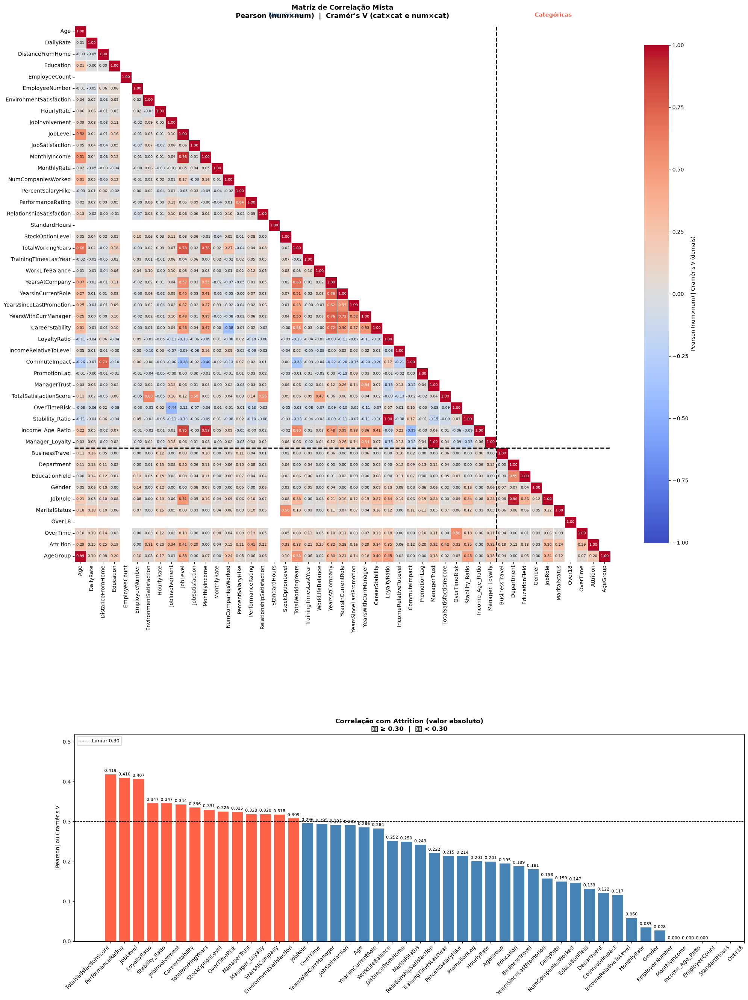


TOP CORRELAÇÕES COM ATTRITION
TotalSatisfactionScore      0.419136
PerformanceRating           0.410309
JobLevel                    0.406929
LoyaltyRatio                0.346605
Stability_Ratio             0.346605
JobInvolvement              0.343781
CareerStability             0.335760
TotalWorkingYears           0.330904
StockOptionLevel            0.326027
OverTimeRisk                0.324738
ManagerTrust                0.319586
Manager_Loyalty             0.319586
YearsAtCompany              0.318211
EnvironmentSatisfaction     0.308534
JobRole                     0.296214
OverTime                    0.294710
YearsWithCurrManager        0.292539
JobSatisfaction             0.291620
Age                         0.286287
YearsInCurrentRole          0.283641
WorkLifeBalance             0.252261
DistanceFromHome            0.250182
MaritalStatus               0.242856
RelationshipSatisfaction    0.221955
TrainingTimesLastYear       0.214670
PercentSalaryHike           0.214435
Promoti

In [25]:
# ================================================
# Matriz de Correlação Mista: Pearson + Cramér's V 
# Cramer's V para dados categóricos
# ================================================

num_cols = df2.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df2.select_dtypes(include=['object']).columns.tolist()
all_cols = num_cols + cat_cols

n = len(all_cols)
corr_matrix = pd.DataFrame(np.zeros((n, n)), index=all_cols, columns=all_cols)

for col_a in all_cols:
    for col_b in all_cols:

        a_is_num = col_a in num_cols
        b_is_num = col_b in num_cols

        if col_a == col_b:
            corr_matrix.loc[col_a, col_b] = 1.0

        elif a_is_num and b_is_num:
            corr_matrix.loc[col_a, col_b] = df2[col_a].corr(df2[col_b])

        else:
            v = cramers_v(df2[col_a].astype(str), df2[col_b].astype(str))
            corr_matrix.loc[col_a, col_b] = v
            corr_matrix.loc[col_b, col_a] = v

corr_matrix = corr_matrix.astype(float)

# ── Visualização: 2 linhas × 1 coluna ────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(20, 30),
                          gridspec_kw={'height_ratios': [4, 1]})

# ── Plot 1: Heatmap completo ──────────────────────────────────────────────
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)

sns.heatmap(
    corr_matrix,
    mask=mask,
    ax=axes[0],
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    annot=True, fmt='.2f',
    annot_kws={'size': 7},
    linewidths=0.4,
    square=True,
    cbar_kws={'label': "Pearson (num×num) | Cramér's V (demais)", 'shrink': 0.6}
)

n_num = len(num_cols)
axes[0].axhline(n_num, color='black', linewidth=2, linestyle='--')
axes[0].axvline(n_num, color='black', linewidth=2, linestyle='--')

axes[0].text(n_num / 2, -0.8, 'Numéricas', ha='center',
             fontsize=11, fontweight='bold', color='steelblue')
axes[0].text(n_num + len(cat_cols) / 2, -0.8, 'Categóricas', ha='center',
             fontsize=11, fontweight='bold', color='tomato')

axes[0].set_title("Matriz de Correlação Mista\nPearson (num×num)  |  Cramér's V (cat×cat e num×cat)",
                   fontsize=13, fontweight='bold', pad=15)
axes[0].tick_params(axis='x', rotation=90)
axes[0].tick_params(axis='y', rotation=0)

# ── Plot 2: Ranking de correlação com Attrition ───────────────────────────
if 'Attrition' in all_cols:
    attrition_corr = (
        corr_matrix['Attrition']
        .drop('Attrition')
        .abs()
        .sort_values(ascending=False)
    )

    colors = ['tomato' if v >= 0.3 else 'steelblue' for v in attrition_corr.values]

    axes[1].bar(attrition_corr.index, attrition_corr.values,
                color=colors, edgecolor='white', linewidth=0.8)
    axes[1].axhline(0.3, color='black', linestyle='--',
                    linewidth=1, label='Limiar 0.30')

    for i, (feat, val) in enumerate(attrition_corr.items()):
        axes[1].text(i, val + 0.005, f'{val:.3f}',
                     ha='center', fontsize=8, color='black')

    axes[1].set_title("Correlação com Attrition (valor absoluto)\n🔴 ≥ 0.30  |  🔵 < 0.30",
                       fontsize=12, fontweight='bold')
    axes[1].set_ylabel("|Pearson| ou Cramér's V")
    axes[1].set_xticks(range(len(attrition_corr)))
    axes[1].set_xticklabels(attrition_corr.index, rotation=45, ha='right')
    axes[1].set_ylim(0, attrition_corr.max() + 0.1)
    axes[1].legend(fontsize=9)

plt.tight_layout(h_pad=4)
plt.show()

# --- Resumo textual ---
print(f"\n{'='*50}")
print("TOP CORRELAÇÕES COM ATTRITION")
print(f"{'='*50}")
print(attrition_corr.to_string())


## 7.0 Feature Selection

### 7.1 Filter Method

In [26]:
from sklearn.feature_selection import VarianceThreshold

# Remove variáveis com variância abaixo do threshold
selector = VarianceThreshold(threshold=0.01)
X_filtered = selector.fit_transform(df2[num_attributes_fe])

# Verificar variância manualmente
variances = df2[num_attributes_fe].var()
low_var_cols = variances[variances < 0.01].index.tolist()
print("Variáveis com variância quasi-zero:", low_var_cols)

Variáveis com variância quasi-zero: ['EmployeeCount', 'StandardHours', 'CommuteImpact']


In [27]:
# Features com baixa variancia
low_variance = ["EmployeeCount", "StandardHours", ]

# low_discrimination_vars
# low_discrimination_cat_vars

# Variáveis com Baixo AUC na analise numerica bivariada
low_bivariate_discriminative = ['DistanceFromHome', 'EmployeeNumber', 'HourlyRate', 'MonthlyRate', 'PercentSalaryHike', 'Stability_Ratio', 'LoyaltyRatio', 'IncomeRelativeToLevel', 'PromotionLag']

# Variáveis com Baixo AUC na analise categica bivariada
low_bivariate_cat_discriminative = ['BusinessTravel', 'EducationField', 'Gender', 'Over18', 'AgeGroup']

auto_corr = ['AgeGroup', 'Department', 'Income_Age_Ratio', 'ManagerTrust', 'JobLevel']


### 7.3 Boruta

In [28]:
from boruta import BorutaPy
import sklearn.ensemble as en


# preparacao dados
X = df2.drop( columns='Attrition' )
y = df2['Attrition'].apply( lambda x: 1 if x == 'Yes' else 0 )

X_boruta = pd.get_dummies( X, prefix_sep='__SEP__' )

# algoritmo
rf = en.RandomForestClassifier(n_jobs=-1, max_depth=5, random_state=42)

# boruta
boruta = BorutaPy( rf, 
                   n_estimators='auto',
                   verbose=2,
                   random_state=42
).fit( X_boruta.values, y.values )

# resultados
confirmed_boruta = X_boruta.columns[boruta.support_].tolist()
tentative_boruta = X_boruta.columns[boruta.support_weak_].tolist()
rejected_boruta = X_boruta.columns[~boruta.support_ & ~boruta.support_weak_].tolist()

# --- Reverter dummies para nome original
def to_original( col ):
    return col.split( '__SEP__' )[0] if '__SEP__' in col else col

confirmed_boruta = sorted( set( to_original( c ) for c in confirmed_boruta ) )
tentative_boruta = sorted( set( to_original( c ) for c in tentative_boruta ) )
rejected_boruta  = sorted( set( to_original( c ) for c in rejected_boruta ) )

# Categórica só é "rejeitada" se TODAS as suas dummies foram rejeitadas.
# Se ao menos uma dummy foi confirmada/tentativa, removemos a original da lista de rejeitadas.
rejected_boruta = [ c for c in rejected_boruta
                      if c not in confirmed_boruta and c not in tentative_boruta ]

print( f'Variaveis confirmadas (originais): {confirmed_boruta}' )
print( f'Variaveis tentativas (originais):  {tentative_boruta}' )
print( f'Variaveis rejeitadas (originais):  {rejected_boruta}' )


# --- 1) Filter Method
rejected_columns = ( low_variance 
                    + low_discrimination_vars  
                    + low_bivariate_discriminative 
                    + low_bivariate_cat_discriminative 
                    + auto_corr
                    + rejected_boruta )

Iteration: 	1 / 100
Confirmed: 	0
Tentative: 	69
Rejected: 	0
Iteration: 	2 / 100
Confirmed: 	0
Tentative: 	69
Rejected: 	0
Iteration: 	3 / 100
Confirmed: 	0
Tentative: 	69
Rejected: 	0
Iteration: 	4 / 100
Confirmed: 	0
Tentative: 	69
Rejected: 	0
Iteration: 	5 / 100
Confirmed: 	0
Tentative: 	69
Rejected: 	0
Iteration: 	6 / 100
Confirmed: 	0
Tentative: 	69
Rejected: 	0
Iteration: 	7 / 100
Confirmed: 	0
Tentative: 	69
Rejected: 	0
Iteration: 	8 / 100
Confirmed: 	31
Tentative: 	8
Rejected: 	30
Iteration: 	9 / 100
Confirmed: 	31
Tentative: 	8
Rejected: 	30
Iteration: 	10 / 100
Confirmed: 	31
Tentative: 	8
Rejected: 	30
Iteration: 	11 / 100
Confirmed: 	31
Tentative: 	8
Rejected: 	30
Iteration: 	12 / 100
Confirmed: 	31
Tentative: 	8
Rejected: 	30
Iteration: 	13 / 100
Confirmed: 	31
Tentative: 	8
Rejected: 	30
Iteration: 	14 / 100
Confirmed: 	31
Tentative: 	7
Rejected: 	31
Iteration: 	15 / 100
Confirmed: 	31
Tentative: 	7
Rejected: 	31
Iteration: 	16 / 100
Confirmed: 	31
Tentative: 	7
Reject

In [29]:
# dropando as variaveis rejeitadas pelo boruta
df3 = df2.drop( columns=rejected_columns )
df3

,Age,DailyRate,EnvironmentSatisfaction,JobInvolvement,JobSatisfaction,MaritalStatus,MonthlyIncome,OverTime,PerformanceRating,RelationshipSatisfaction,...,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsWithCurrManager,Attrition,CareerStability,CommuteImpact,TotalSatisfactionScore,OverTimeRisk,Manager_Loyalty
241,43,807,3,2,3,Married,2437,Yes,3,4,...,3,1,0,0,Yes,0.600000,0.006976,13,1,0.000000
110,31,1062,4,2,2,Single,2070,Yes,2,0,...,4,3,1,2,Yes,1.000000,0.000483,10,1,0.666664
1523,30,330,3,1,1,Single,6655,No,3,2,...,1,5,2,1,Yes,1.333333,0.003907,7,0,0.200000
1707,31,874,3,3,3,Married,2610,No,3,3,...,2,2,2,2,Yes,1.000000,0.005747,11,0,0.999995
122,31,163,4,3,4,Single,5238,No,4,4,...,2,5,4,4,No,3.000000,0.004582,14,0,0.799998
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
270,31,307,3,2,2,Single,3479,No,3,2,...,4,5,4,4,Yes,6.000000,0.008336,11,0,0.799998
756,32,977,4,3,2,Divorced,5470,No,3,3,...,2,9,5,6,No,10.000000,0.000366,11,0,0.666666
1546,31,1079,1,3,3,Married,8161,No,3,1,...,3,1,0,0,Yes,3.333333,0.001961,8,0,0.000000
466,34,204,3,3,3,Divorced,2579,Yes,3,4,...,3,8,2,6,No,4.000000,0.005428,13,0,0.749999


### 7.3 RFE

In [30]:
from sklearn.feature_selection import RFE, RFECV
from sklearn.ensemble import RandomForestClassifier


# Preparação simplificada para o Boruta (Encoding Temporário)
X = df2.drop(columns=['Attrition'])
y = df2['Attrition'].apply(lambda x: 1 if x == 'Yes' else 0)

X_rfe = pd.get_dummies(X)

# RFE com número fixo de features
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rfe = RFE(estimator=rf, n_features_to_select=10, step=1)
rfe.fit(X_rfe, y)

features_selecionadas = X_rfe.columns[rfe.support_].tolist()
print("Features selecionadas pelo RFE:", features_selecionadas)

# RFECV: encontra automaticamente o número ótimo via cross-validation
rfecv = RFECV(
    estimator=rf,
    step=1,
    cv=5,
    scoring='roc_auc',
    min_features_to_select=5
)
rfecv.fit(X_rfe, y)

print(f"Número ótimo de features: {rfecv.n_features_}")
print("Features:", X_rfe.columns[rfecv.support_].tolist())

Features selecionadas pelo RFE: ['Age', 'EmployeeNumber', 'MonthlyIncome', 'PerformanceRating', 'CareerStability', 'IncomeRelativeToLevel', 'CommuteImpact', 'TotalSatisfactionScore', 'Income_Age_Ratio', 'Manager_Loyalty']
Número ótimo de features: 60
Features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EmployeeNumber', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'CareerStability', 'LoyaltyRatio', 'IncomeRelativeToLevel', 'CommuteImpact', 'PromotionLag', 'ManagerTrust', 'TotalSatisfactionScore', 'OverTimeRisk', 'Stability_Ratio', 'Income_Age_Ratio', 'Manager_Loyalty', 'BusinessTravel_Non-Travel', 'BusinessTravel_Travel_Frequently', 'Bu

- RFE nao conseguiu selecionar as features de importancia, por isso, seguimos com o boruta.

In [31]:
df4 = df3.copy()

## 8.0 Padronização dos dados

### 8.1 Separação dos dados em treino teste

In [32]:
from sklearn.model_selection import train_test_split

# Convert response variable from categorial to numerical
df4['Attrition'] = df4["Attrition"].apply(lambda x: 1 if x == "Yes" else 0)

X = df4.drop('Attrition', axis=1)
y = df4['Attrition']

# Train and Validation Split
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

### 8.2 Avaliação de normalidade

In [33]:
from scipy import stats
from sklearn import preprocessing as pp

num_cols = X_train.select_dtypes( include=['int64', 'float64'] ).columns.tolist()
cat_cols = X_train.select_dtypes( include=['object'] ).columns.tolist()

results_norm = []
for col in num_cols:
    series = X_train[col].dropna()

    # Shapiro-Wilk
    _, sw_p = stats.shapiro( series )

    # Kolmogorov-Smirnov vs normal padronizada
    z = ( series - series.mean() ) / series.std( ddof=0 )
    _, ks_p = stats.kstest( z, 'norm' )

    results_norm.append({
        'Feature': col,
        'Shapiro_p': sw_p,
        'KS_p': ks_p,
        'Normal_alpha_0.05': 'Yes' if (sw_p > 0.05) and (ks_p > 0.05) else 'No'
    })

df_normality = pd.DataFrame( results_norm ).sort_values( by='Shapiro_p', ascending=False )

df_normality.style.format({
    'Shapiro_p': '{:.4f}',
    'KS_p': '{:.4f}'
}).background_gradient( subset=['Shapiro_p', 'KS_p'], cmap='RdYlGn' )

,Feature,Shapiro_p,KS_p,Normal_alpha_0.05
0,Age,0.0000,0.0000,No
17,TotalSatisfactionScore,0.0000,0.0000,No
1,DailyRate,0.0000,0.0000,No
10,TrainingTimesLastYear,0.0000,0.0000,No
9,TotalWorkingYears,0.0000,0.0000,No
19,Manager_Loyalty,0.0000,0.0000,No
13,YearsInCurrentRole,0.0000,0.0000,No
14,YearsWithCurrManager,0.0000,0.0000,No
7,RelationshipSatisfaction,0.0000,0.0000,No
2,EnvironmentSatisfaction,0.0000,0.0000,No


### 8.3 Padronização

In [34]:
# Rescaling
robust_cols = ['JobInvolvement', 'MonthlyIncome', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 
               'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany','YearsInCurrentRole', 'YearsWithCurrManager', 'CareerStability', 
               'CommuteImpact', 'TotalSatisfactionScore', 'OverTimeRisk', 'Manager_Loyalty']
min_max_cols = ['Age', 'EnvironmentSatisfaction']

rs = pp.RobustScaler()
X_train[robust_cols] = rs.fit_transform(X_train[robust_cols])
X_val[robust_cols] = rs.transform(X_val[robust_cols])

mms = pp.MinMaxScaler()
X_train[min_max_cols] = mms.fit_transform(X_train[min_max_cols])
X_val[min_max_cols] = mms.transform(X_val[min_max_cols])


### 8.4 Encoder

In [35]:
# Encoder
one_hot_cols = ['MaritalStatus', 'OverTime']
ohe = pp.OneHotEncoder(sparse_output=False, handle_unknown='ignore', drop='if_binary') # Drop binário dropa colunas 0 ou 1, reduzindo uma coluna, pois coluna de 0 e 1 nao precisam serem convertidas em 2 colunas

X_train_encoded = ohe.fit_transform(X_train[one_hot_cols])

X_train_encoded_df = pd.DataFrame(
    X_train_encoded,
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=X_train.index
)

X_val_encoded = ohe.transform(X_val[one_hot_cols])
X_val_encoded_df = pd.DataFrame(
    X_val_encoded,
    columns=ohe.get_feature_names_out(one_hot_cols),
    index=X_val.index
)

X_train = pd.concat([X_train.drop(columns=one_hot_cols), X_train_encoded_df], axis=1)
X_val = pd.concat([X_val.drop(columns=one_hot_cols), X_val_encoded_df], axis=1)

## 9.0 Machine Learning Modeling

### 9.1 Baseline Model

In [36]:
from sklearn import metrics as mt

def ml_metrics( model_name, y_true, y_prob, threshold=0.5):
    y_pred = [ 1 if x > threshold else 0 for x in y_prob ]
    acc = mt.accuracy_score( y_true, y_pred )
    f1 = mt.f1_score( y_true, y_pred, zero_division=0 )
    prec = mt.precision_score( y_true, y_pred, zero_division=0 )
    rec = mt.recall_score( y_true, y_pred, zero_division=0 )
    auc = mt.roc_auc_score( y_true, y_prob )

    return pd.DataFrame({
        'Model Name': model_name,
        'Accuracy': acc,
        'F1-Score': f1,
        'Precision': prec,
        'Recall': rec,
        'AUC': auc
    }, index=[0] )

- O modelo vai ter como output uma probabilidade de 0 a 1.
- Temos que converter essa probabilidade em duas variáveis (0 e 1), removendo os intervalos
- O threshold quem seta esse limite, por padrão é 0.5

In [37]:
yhat_baseline_train = np.random.choice( [0.1, 0.9], size=len(y_train), p=[0.5, 0.5] )
yhat_baseline_val = np.random.choice( [0.1, 0.9], size=len(y_val), p=[0.5, 0.5] )

baseline_train = ml_metrics('Baseline Train', y_train, yhat_baseline_train )
baseline_val = ml_metrics('Baseline Val', y_val, yhat_baseline_val )

baseline = pd.concat( [baseline_train, baseline_val] )
baseline

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Baseline Train,0.501776,0.367531,0.296364,0.483680,0.496593
0,Baseline Val,0.517730,0.352381,0.296000,0.435294,0.494297


## 9.2 Regressão Logística

In [38]:
from sklearn.linear_model import LogisticRegressionCV

# Busca automática do melhor C
model_cv = LogisticRegressionCV(
    Cs=[0.001, 0.01, 0.1, 1, 10, 100],
    cv=5,
    scoring='roc_auc',
    solver='lbfgs',
    max_iter=1000,
    random_state=42
)
model_cv.fit(X_train, y_train)
print(f"Melhor C encontrado: {model_cv.C_[0]:.4f}")

Melhor C encontrado: 1.0000


In [ ]:
from sklearn.linear_model import LogisticRegression

# Definição
lr_model = LogisticRegression(
    C=model_cv.C_[0],              # C = 1/λ → inverso da regularização L2
    solver='lbfgs',     # otimizador (quasi-Newton)
    max_iter=1000,      # máximo de iterações
    random_state=42
)

# Treinamento
lr_model.fit(X_train, y_train)

# Acessar os coeficientes aprendidos
print("Pesos (W):", lr_model.coef_)
print("Bias (b):", lr_model.intercept_)
print("#"*60)

# Previsão
y_hat_lr_train  = lr_model.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_lr_val  = lr_model.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
lr_train = ml_metrics("Logistic Regression Train", y_train, y_hat_lr_train)
lr_val = ml_metrics("Logistic Regression Val", y_val, y_hat_lr_val)



In [40]:
lr = pd.concat([lr_train, lr_val])
lr

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Logistic Regression Train,0.873002,0.771930,0.834483,0.718101,0.907504
0,Logistic Regression Val,0.826241,0.671141,0.781250,0.588235,0.872141


- Com .predict --> Já traz os resultados totais (0 e 1), considerando a função sigmoid
- Com .predict_proba --> Traz as probabilidades (intervalo entre 0 e 1), fica mais fácil para ajuste de threshold

## 9.3 Random Forest

In [41]:
# Grid de busca - Fine Tunning
param_dist = {
    'n_estimators':      [100, 200, 300, 500],
    'max_features':      ['sqrt', 'log2', 0.3, 0.5],
    'max_depth':         [None, 5, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf':  [1, 2, 4],
    'class_weight':      [None, 'balanced']
}


In [42]:
from sklearn.model_selection import RandomizedSearchCV
import numpy as np


# Definição
rf = RandomForestClassifier(n_jobs=-1, random_state=42)

rf_search = RandomizedSearchCV(
    rf, param_dist,
    n_iter=50,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Treinamento
rf_search.fit(X_train, y_train)

print(f"Melhores hiperparâmetros: {rf_search.best_params_}")
print(f"Melhor AUC CV: {rf_search.best_score_:.4f}")

best_model = rf_search.best_estimator_

# Previsão
y_hat_rf_train  = rf_search.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_rf_val  = rf_search.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
rf_train = ml_metrics("Random Forest Train", y_train, y_hat_rf_train)
rf_val = ml_metrics("Random Forest Val", y_val, y_hat_rf_val)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Melhores hiperparâmetros: {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced'}
Melhor AUC CV: 0.9318


In [43]:
rf = pd.concat([rf_train, rf_val])
rf

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Random Forest Train,0.993783,0.989721,0.979651,1.000000,1.000000
0,Random Forest Val,0.865248,0.762500,0.813333,0.717647,0.901583


## 9.4 XGBOOST

In [44]:
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

# Grid de busca balanceado
param_dist = {
    'n_estimators':      [500, 1000, 2000],
    'learning_rate':     [0.01, 0.05, 0.1],
    'max_depth':         [3, 4, 5, 6],
    'min_child_weight':  [1, 3, 5, 10],
    'subsample':         [0.6, 0.7, 0.8, 0.9],
    'colsample_bytree':  [0.6, 0.7, 0.8, 0.9],
    'reg_lambda':        [0.1, 1.0, 5.0, 10.0],
    'reg_alpha':         [0.0, 0.1, 0.5, 1.0],
    'gamma':             [0.0, 0.1, 0.5, 1.0]
}

# Definição
xgb_model = xgb.XGBClassifier(
    eval_metric='auc',
    class_weight = 'balanced',
    use_label_encoder=False,
    early_stopping_rounds=50,
    random_state=42,
    n_jobs=-1
)

xgboost_search = RandomizedSearchCV(
    xgb_model, param_dist,
    n_iter=60,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Treinamento
xgboost_search.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print(f"Melhores hiperparâmetros: {xgboost_search.best_params_}")
print(f"Melhor AUC CV:  {xgboost_search.best_score_:.4f}")
print(f"AUC Validação:  {roc_auc_score(y_val, xgboost_search.best_estimator_.predict_proba(X_val)[:,1]):.4f}")

# Previsão
y_hat_xgboost_train  = xgboost_search.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_xgboost_val  = xgboost_search.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
xgboost_train = ml_metrics("XGBOOST Train", y_train, y_hat_xgboost_train)
xgboost_val = ml_metrics("XGBOOST Val", y_val, y_hat_xgboost_val)

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Melhores hiperparâmetros: {'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'n_estimators': 2000, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.05, 'gamma': 0.0, 'colsample_bytree': 0.7}
Melhor AUC CV:  0.9340
AUC Validação:  0.9012


In [45]:
xgboost = pd.concat([xgboost_train, xgboost_val])
xgboost

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,XGBOOST Train,0.960924,0.931250,0.983498,0.884273,0.995367
0,XGBOOST Val,0.861702,0.748387,0.828571,0.682353,0.901224


In [46]:
## Com bayesian search - optuna

In [ ]:
import optuna
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score
import numpy as np

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    """Função objetivo: cada chamada treina e avalia uma combinação"""
    params = {
        'n_estimators':       trial.suggest_int('n_estimators', 100, 2000),
        'learning_rate':      trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'max_depth':          trial.suggest_int('max_depth', 3, 10),
        'min_child_weight':   trial.suggest_int('min_child_weight', 1, 20),
        'subsample':          trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':   trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_lambda':         trial.suggest_float('reg_lambda', 0.01, 10.0, log=True),
        'reg_alpha':          trial.suggest_float('reg_alpha', 0.001, 1.0, log=True),
        'use_label_encoder':  False,
        'eval_metric':        'auc',
        'random_state':       42,
        'n_jobs':             -1
    }

    model = XGBClassifier(**params)
    scores = cross_val_score(
        model, X_train, y_train,
        scoring='recall',
        cv=5,
        n_jobs=-1
    )
    return scores.mean()

# Criar e executar o estudo
study = optuna.create_study(
    direction='maximize',                        # maximizar AUC
    sampler=optuna.samplers.TPESampler(seed=42)  # Tree Parzen Estimator
)

study.optimize(
    objective,
    n_trials=50,        # número de avaliações
    timeout=3600,        # limite de 1 hora (opcional)
    show_progress_bar=True
)

# Resultados
print(f"Melhor AUC (CV):     {study.best_value:.4f}")
print(f"Melhores parâmetros: {study.best_params}")

# Retreinar com os melhores parâmetros no treino completo
best_model = XGBClassifier(**study.best_params,
                            use_label_encoder=False,
                            eval_metric='auc',
                            random_state=42,
                            n_jobs=-1)
best_model.fit(X_train, y_train)
print(f"AUC Validação: {roc_auc_score(y_val, best_model.predict_proba(X_val)[:,1]):.4f}")

  0%|          | 0/50 [00:00<?, ?it/s]

Best trial: 46. Best value: 0.777392: 100%|██████████| 50/50 [02:01<00:00,  2.43s/it, 121.69/3600 seconds]


Melhor AUC (CV):     0.7774
Melhores parâmetros: {'n_estimators': 630, 'learning_rate': 0.04044905955958506, 'max_depth': 9, 'min_child_weight': 2, 'subsample': 0.8674211909681765, 'colsample_bytree': 0.589326033892033, 'reg_lambda': 0.6922609566766508, 'reg_alpha': 0.0028605723382090077}
AUC Validação: 0.8994


In [55]:
# Previsão
y_hat_xgboost_train  = best_model.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_xgboost_val  = best_model.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
xgboost_train = ml_metrics("XGBOOST Train", y_train, y_hat_xgboost_train)
xgboost_val = ml_metrics("XGBOOST Val", y_val, y_hat_xgboost_val)

xgboost = pd.concat([xgboost_train, xgboost_val])
xgboost

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,XGBOOST Train,1.000000,1.00000,1.000000,1.000000,1.000000
0,XGBOOST Val,0.847518,0.72956,0.783784,0.682353,0.899373


## 9.5 LGBM

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score

param_dist = {
    'n_estimators':       [500, 1000, 2000],
    'learning_rate':      [0.01, 0.05, 0.1],
    'num_leaves':         [15, 31, 63, 127],
    'max_depth':          [-1, 5, 8, 12],
    'min_child_samples':  [10, 20, 50, 100],
    'subsample':          [0.6, 0.7, 0.8, 0.9],
    'colsample_bytree':   [0.6, 0.7, 0.8, 0.9],
    'reg_lambda':         [0.0, 0.1, 1.0, 5.0],
    'reg_alpha':          [0.0, 0.1, 0.5, 1.0],
    'max_bin':            [127, 255, 511]
}

# Definição
lgbm = LGBMClassifier(
    boosting_type='gbdt',
    class_weight = 'balanced',
    objective='binary',
    metric='auc',
    n_jobs=-1,
    random_state=42,
    verbose=-1
)

lgbm_search = RandomizedSearchCV(
    lgbm, param_dist,
    n_iter=60,
    scoring='roc_auc',
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

# Treinamento
lgbm_search.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)]
    # callbacks=[lgbm.early_stopping(50, verbose=False)]
)

print(f"Melhores hiperparâmetros: {lgbm_search.best_params_}")
print(f"Melhor AUC CV:  {lgbm_search.best_score_:.4f}")
print(f"AUC Validação:  {roc_auc_score(y_val, lgbm_search.best_estimator_.predict_proba(X_val)[:,1]):.4f}")


# Previsão
y_hat_lgbm_train  = lgbm_search.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_lgbm_val  = lgbm_search.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
lgbm_train = ml_metrics("LGBM Train", y_train, y_hat_lgbm_train)
lgbm_val = ml_metrics("LGBM Val", y_val, y_hat_lgbm_val)

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Melhores hiperparâmetros: {'subsample': 0.8, 'reg_lambda': 1.0, 'reg_alpha': 0.0, 'num_leaves': 127, 'n_estimators': 2000, 'min_child_samples': 20, 'max_depth': -1, 'max_bin': 255, 'learning_rate': 0.1, 'colsample_bytree': 0.6}
Melhor AUC CV:  0.9354
AUC Validação:  0.8950


In [ ]:
lgbm = pd.concat([lgbm_train, lgbm_val])
lgbm

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,LGBM Train,1.000000,1.000000,1.000000,1.000000,1.000000
0,LGBM Val,0.843972,0.728395,0.766234,0.694118,0.895013


In [ ]:
## Bayesian search - com optuna

In [ ]:
import optuna
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import roc_auc_score
import numpy as np

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    """Função objetivo: cada chamada treina e avalia uma combinação"""
    params = {
        'n_estimators':       trial.suggest_int('n_estimators', 100, 2000),
        'learning_rate':      trial.suggest_float('learning_rate', 0.005, 0.3, log=True),
        'max_depth':          trial.suggest_int('max_depth', 3, 10),
        'min_child_weight':   trial.suggest_int('min_child_weight', 1, 20),
        'subsample':          trial.suggest_float('subsample', 0.5, 1.0),
        'colsample_bytree':   trial.suggest_float('colsample_bytree', 0.5, 1.0),
        'reg_lambda':         trial.suggest_float('reg_lambda', 0.01, 10.0, log=True),
        'reg_alpha':          trial.suggest_float('reg_alpha', 0.001, 1.0, log=True),
        'use_label_encoder':  False,
        'eval_metric':        'auc',
        'random_state':       42,
        'n_jobs':             -1
    }

    model = LGBMClassifier(**params)
    scores = cross_val_score(
        model, X_train, y_train,
        scoring='roc_auc',
        class_weight = 'balanced',
        cv=5,
        n_jobs=-1
    )
    return scores.mean()

# Criar e executar o estudo
study = optuna.create_study(
    direction='maximize',                        # maximizar AUC
    sampler=optuna.samplers.TPESampler(seed=42)  # Tree Parzen Estimator
)

study.optimize(
    objective,
    n_trials=100,        # número de avaliações
    timeout=3600,        # limite de 1 hora (opcional)
    show_progress_bar=True
)

# Resultados
print(f"Melhor AUC (CV):     {study.best_value:.4f}")
print(f"Melhores parâmetros: {study.best_params}")

# Retreinar com os melhores parâmetros no treino completo
best_model = LGBMClassifier(**study.best_params,
                            use_label_encoder=False,
                            eval_metric='auc',
                            random_state=42,
                            n_jobs=-1)
best_model.fit(X_train, y_train)
print(f"AUC Validação: {roc_auc_score(y_val, best_model.predict_proba(X_val)[:,1]):.4f}")

  0%|          | 0/100 [00:00<?, ?it/s]

Best trial: 65. Best value: 0.777349: 100%|██████████| 100/100 [04:00<00:00,  2.41s/it, 240.97/3600 seconds]


Melhor AUC (CV):     0.7773
Melhores parâmetros: {'n_estimators': 1396, 'learning_rate': 0.04501726120446916, 'max_depth': 7, 'min_child_weight': 3, 'subsample': 0.8642024126097431, 'colsample_bytree': 0.6432272891100326, 'reg_lambda': 0.01930816497157059, 'reg_alpha': 0.27359630812808705}
AUC Validação: 0.8826


In [ ]:
# Previsão
y_hat_lgbm_train  = best_model.predict_proba(X_train)[:, 1]  # P(y=1)
y_hat_lgbm_val  = best_model.predict_proba(X_val)    [:,1]          # classe predita

# Desempenho
lgbm_train = ml_metrics("LGBM Train", y_train, y_hat_lgbm_train)
lgbm_val = ml_metrics("LGBM Val", y_val, y_hat_lgbm_val)

lgbm = pd.concat([lgbm_train, lgbm_val])
lgbm

,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,LGBM Train,1.000000,1.000,1.000000,1.000000,1.000000
0,LGBM Val,0.843972,0.725,0.773333,0.682353,0.882592


In [62]:
# ============================================================
# COMPARACAO JUSTA: RandomizedSearchCV vs Optuna (TPE)
# Mesmo estimador, mesmo espaco de busca, mesmo orcamento (60),
# mesma metrica otimizada (RECALL).
# ============================================================
from lightgbm import LGBMClassifier
from sklearn.model_selection import RandomizedSearchCV, cross_val_score, StratifiedKFold
import numpy as np
import optuna

N_AVALIACOES = 60          # orcamento identico nos dois metodos
SEED = 42
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)  # mesma particao p/ os dois

# Parametros FIXOS do estimador base (iguais nos dois metodos)
PARAMS_FIXOS = dict(
    boosting_type='gbdt',
    class_weight='balanced',   # agora presente nos DOIS -> comparacao justa
    objective='binary',
    n_jobs=-1,
    random_state=SEED,
    verbose=-1,
)


In [63]:
# ---------- RandomizedSearchCV ----------
param_dist = {
    'n_estimators':      [500, 1000, 2000],
    'learning_rate':     [0.01, 0.05, 0.1],
    'num_leaves':        [15, 31, 63, 127],
    'max_depth':         [-1, 5, 8, 12],
    'min_child_samples': [10, 20, 50, 100],
    'subsample':         [0.6, 0.7, 0.8, 0.9],
    'colsample_bytree':  [0.6, 0.7, 0.8, 0.9],
    'reg_lambda':        [0.0, 0.1, 1.0, 5.0],
    'reg_alpha':         [0.0, 0.1, 0.5, 1.0],
}

lgbm = LGBMClassifier(**PARAMS_FIXOS)

lgbm_search = RandomizedSearchCV(
    lgbm, param_dist,
    n_iter=N_AVALIACOES,     # mesmo orcamento do Optuna
    scoring='recall',        # otimiza RECALL (objetivo real)
    cv=CV,
    random_state=SEED,
    n_jobs=-1,
    verbose=1,
)

lgbm_search.fit(X_train, y_train)   # nada de eval_set aqui: CV ja faz a validacao interna

print(f"[RandomSearch] melhor Recall (CV): {lgbm_search.best_score_:.4f}")
print(f"[RandomSearch] melhores params:    {lgbm_search.best_params_}")

# probabilidades p/ o ml_metrics
rs_prob_train = lgbm_search.predict_proba(X_train)[:, 1]
rs_prob_val   = lgbm_search.predict_proba(X_val)[:, 1]

rs_train = ml_metrics("RandomSearch Train", y_train, rs_prob_train)
rs_val   = ml_metrics("RandomSearch Val",   y_val,   rs_prob_val)


Fitting 5 folds for each of 60 candidates, totalling 300 fits
[RandomSearch] melhor Recall (CV): 0.8130
[RandomSearch] melhores params:    {'subsample': 0.9, 'reg_lambda': 1.0, 'reg_alpha': 1.0, 'num_leaves': 63, 'n_estimators': 1000, 'min_child_samples': 100, 'max_depth': -1, 'learning_rate': 0.01, 'colsample_bytree': 0.6}


In [ ]:
# ---------- Optuna (TPE) ----------
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    # MESMO espaco de busca do RandomSearch (via suggest_categorical)
    params = {
        'n_estimators':      trial.suggest_categorical('n_estimators',      [500, 1000, 2000]),
        'learning_rate':     trial.suggest_categorical('learning_rate',     [0.01, 0.05, 0.1]),
        'num_leaves':        trial.suggest_categorical('num_leaves',        [15, 31, 63, 127]),
        'max_depth':         trial.suggest_categorical('max_depth',         [-1, 5, 8, 12]),
        'min_child_samples': trial.suggest_categorical('min_child_samples', [10, 20, 50, 100]),
        'subsample':         trial.suggest_categorical('subsample',         [0.6, 0.7, 0.8, 0.9]),
        'colsample_bytree':  trial.suggest_categorical('colsample_bytree',  [0.6, 0.7, 0.8, 0.9]),
        'reg_lambda':        trial.suggest_categorical('reg_lambda',        [0.0, 0.1, 1.0, 5.0]),
        'reg_alpha':         trial.suggest_categorical('reg_alpha',         [0.0, 0.1, 0.5, 1.0]),
    }

    model = LGBMClassifier(**PARAMS_FIXOS, **params)   # inclui class_weight='balanced'
    scores = cross_val_score(
        model, X_train, y_train,
        scoring='recall',    # MESMA metrica do RandomSearch
        cv=CV,               # MESMA particao
        n_jobs=-1,
    )
    return scores.mean()

study = optuna.create_study(
    direction='maximize',
    sampler=optuna.samplers.TPESampler(seed=SEED),
)
study.optimize(objective, n_trials=N_AVALIACOES, show_progress_bar=True)  # mesmo orcamento

print(f"[Optuna] melhor Recall (CV): {study.best_value:.4f}")
print(f"[Optuna] melhores params:    {study.best_params}")

# IMPORTANTE: retreina com os FIXOS + os melhores do espaco de busca
# (senao perde class_weight='balanced' e a comparacao deixa de ser justa)
best_model = LGBMClassifier(**PARAMS_FIXOS, **study.best_params)
best_model.fit(X_train, y_train)

op_prob_train = best_model.predict_proba(X_train)[:, 1]
op_prob_val   = best_model.predict_proba(X_val)[:, 1]

op_train = ml_metrics("Optuna Train", y_train, op_prob_train)
op_val   = ml_metrics("Optuna Val",   y_val,   op_prob_val)


Best trial: 28. Best value: 0.813169: 100%|██████████| 60/60 [07:00<00:00,  7.01s/it]


[Optuna] melhor Recall (CV): 0.8132
[Optuna] melhores params:    {'n_estimators': 2000, 'learning_rate': 0.01, 'num_leaves': 63, 'max_depth': 5, 'min_child_samples': 100, 'subsample': 0.8, 'colsample_bytree': 0.6, 'reg_lambda': 0.0, 'reg_alpha': 0.5}


In [ ]:
# ---------- Tabela comparativa (validacao) ----------
import pandas as pd
comparacao = pd.concat([rs_val, op_val], ignore_index=True)
comparacao


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,RandomSearch Val,0.819149,0.711864,0.684783,0.741176,0.877277
1,Optuna Val,0.826241,0.716763,0.704545,0.729412,0.882293


## 9.6 Comparison models

In [ ]:
print("------ Training metrics --------")
display(pd.concat([lr_train, rf_train, xgboost_train, lgbm_train], ignore_index=True))


print("------ Validation metrics --------")
display(pd.concat([lr_val, rf_val, xgboost_val, lgbm_val], ignore_index=True))

------ Training metrics --------


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Logistic Regression Train,0.873002,0.771930,0.834483,0.718101,0.907504
1,Random Forest Train,0.993783,0.989721,0.979651,1.000000,1.000000
2,XGBOOST Train,0.960924,0.931250,0.983498,0.884273,0.995367
3,LGBM Train,1.000000,1.000000,1.000000,1.000000,1.000000


------ Validation metrics --------


,Model Name,Accuracy,F1-Score,Precision,Recall,AUC
0,Logistic Regression Val,0.826241,0.671141,0.781250,0.588235,0.872141
1,Random Forest Val,0.865248,0.762500,0.813333,0.717647,0.901583
2,XGBOOST Val,0.861702,0.748387,0.828571,0.682353,0.901224
3,LGBM Val,0.843972,0.728395,0.766234,0.694118,0.895013


## Encontrando melhor threshold

Average Precision (AUC-PR): 0.7924
Baseline (taxa de eventos): 0.3014
Ganho sobre baseline:       2.63x


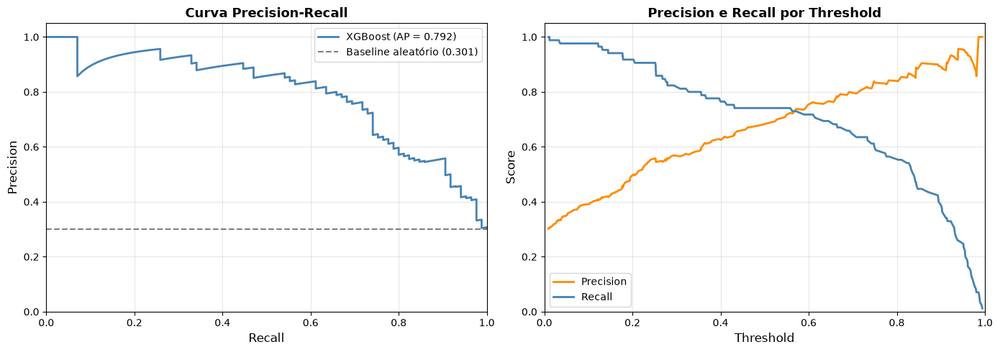

In [65]:
from sklearn import metrics as mt

# Calcular a curva
precisions, recalls, thresholds = mt.precision_recall_curve(y_val, rs_prob_val)
av_precision = mt.average_precision_score(y_val, rs_prob_val)
baseline = y_val.mean()  # precision de um modelo aleatório

print(f"Average Precision (AUC-PR): {av_precision:.4f}")
print(f"Baseline (taxa de eventos): {baseline:.4f}")
print(f"Ganho sobre baseline:       {av_precision/baseline:.2f}x")

# Plotar
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- Curva PR ---
ax1 = axes[0]
ax1.plot(recalls, precisions, color='steelblue', lw=2,
         label=f'XGBoost (AP = {av_precision:.3f})')
ax1.axhline(y=baseline, color='gray', linestyle='--', lw=1.5,
            label=f'Baseline aleatório ({baseline:.3f})')
ax1.set_xlabel('Recall', fontsize=12)
ax1.set_ylabel('Precision', fontsize=12)
ax1.set_title('Curva Precision-Recall', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1.05])
ax1.grid(alpha=0.3)

# --- Precision e Recall por threshold ---
ax2 = axes[1]
ax2.plot(thresholds, precisions[:-1], color='darkorange', lw=2, label='Precision')
ax2.plot(thresholds, recalls[:-1],    color='steelblue',  lw=2, label='Recall')
ax2.set_xlabel('Threshold', fontsize=12)
ax2.set_ylabel('Score', fontsize=12)
ax2.set_title('Precision e Recall por Threshold', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1.05])
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('precision_recall_curve.png', dpi=150, bbox_inches='tight')
plt.show()

In [66]:
# -------------------------------------------------------
# Critério 1: maximizar F1-Score
# (equilíbrio harmônico entre Precision e Recall)
# -------------------------------------------------------
f1_scores = 2 * (precisions[:-1] * recalls[:-1]) / (
    precisions[:-1] + recalls[:-1] + 1e-10
)
best_idx_f1 = np.argmax(f1_scores)
threshold_f1 = thresholds[best_idx_f1]

print("=== Threshold ótimo pelo F1-Score ===")
print(f"Threshold:  {threshold_f1:.4f}")
print(f"F1-Score:   {f1_scores[best_idx_f1]:.4f}")
print(f"Precision:  {precisions[best_idx_f1]:.4f}")
print(f"Recall:     {recalls[best_idx_f1]:.4f}")

# -------------------------------------------------------
# Critério 2: Recall mínimo garantido pelo negócio
# Ex: "quero capturar pelo menos 80% dos fraudes"
# -------------------------------------------------------
recall_minimo = 0.80
mask_recall = recalls[:-1] >= recall_minimo
if mask_recall.any():
    # Dentre os thresholds que atingem o recall mínimo,
    # escolher o que maximiza Precision
    precisions_filtradas = np.where(mask_recall, precisions[:-1], 0)
    best_idx_recall = np.argmax(precisions_filtradas)
    threshold_recall = thresholds[best_idx_recall]

    print(f"\n=== Threshold com Recall ≥ {recall_minimo} ===")
    print(f"Threshold:  {threshold_recall:.4f}")
    print(f"Precision:  {precisions[best_idx_recall]:.4f}")
    print(f"Recall:     {recalls[best_idx_recall]:.4f}")
    print(f"F1-Score:   {f1_scores[best_idx_recall]:.4f}")

# -------------------------------------------------------
# Critério 3: Precision mínima garantida pelo negócio
# Ex: "quero que pelo menos 70% dos alertas sejam verdadeiros"
# -------------------------------------------------------
precision_minima = 0.70
mask_prec = precisions[:-1] >= precision_minima
if mask_prec.any():
    recalls_filtrados = np.where(mask_prec, recalls[:-1], 0)
    best_idx_prec = np.argmax(recalls_filtrados)
    threshold_prec = thresholds[best_idx_prec]

    print(f"\n=== Threshold com Precision ≥ {precision_minima} ===")
    print(f"Threshold:  {threshold_prec:.4f}")
    print(f"Precision:  {precisions[best_idx_prec]:.4f}")
    print(f"Recall:     {recalls[best_idx_prec]:.4f}")
    print(f"F1-Score:   {f1_scores[best_idx_prec]:.4f}")

=== Threshold ótimo pelo F1-Score ===
Threshold:  0.6097
F1-Score:   0.7394
Precision:  0.7625
Recall:     0.7176

=== Threshold com Recall ≥ 0.8 ===
Threshold:  0.3556
Precision:  0.5965
Recall:     0.8000
F1-Score:   0.6834

=== Threshold com Precision ≥ 0.7 ===
Threshold:  0.5280
Precision:  0.7000
Recall:     0.7412
F1-Score:   0.7200
